# 03 · The score-function view: denoising = estimating $\nabla\log p$

Notebook 02 trained a network to predict the noise $\epsilon$ that was added to a data point. This notebook looks at the
same object from a second, equally important angle: the **score** $\nabla_x\log p(x)$, the vector field that points
"uphill" in log-density. Scores let us sample with Langevin dynamics without ever normalising a density; noise makes
scores learnable (denoising score matching) and makes Langevin sampling work on multimodal data (annealing); and
Tweedie's formula shows that the noise predictor, the score and the Bayes-optimal denoiser are one and the same thing.
As in 02, a Gaussian-mixture "lab" with exact scores at every noise level lets us separate model error from sampler error.

**You will learn:**
- what the score is, why it does not need the normalising constant, and what it looks like for a Gaussian mixture
- Langevin dynamics (an MCMC sampler that only needs the score), and its two failure modes on multimodal data
- annealed Langevin dynamics over decreasing noise levels, and why *adding noise* (unlike raising the temperature) preserves mode weights
- explicit vs **denoising score matching**: the one-line identity behind it, and why DDPM's $\epsilon$-loss *is* denoising score matching
- **Tweedie's formula** $\mathbb E[x_0\mid x_t]=(x_t+(1-\bar\alpha_t)\nabla\log q_t(x_t))/\sqrt{\bar\alpha_t}$: the posterior-mean denoiser
- where a learned score is accurate and where it is not; that a perfect score gives near-perfect DDPM samples
- why the *exact* score of a finite training set can only reproduce the training points (or blends of very close neighbours), and how a trained network instead generalises

**Prerequisites:** 01 · The forward process ($q(x_t\mid x_0)$, noised marginals, VP vs VE); 02 · DDPM from scratch
(the $\epsilon$-prediction loss, ancestral sampling, MMD as a sample-quality metric).

**Runtime:** about 3 min on a 4-core laptop CPU (three small MLPs of about 20 s each, plus many exact-score computations);
about 2–3 min on a GPU (the exact Gaussian-mixture computations stay on the CPU).

## Setup

Exact densities and scores of Gaussian mixtures are computed in float64 on the CPU (Apple's MPS backend has no float64).
The Langevin experiments use only exact scores, so they run entirely on the CPU. Neural networks run on `device`.

> **Gotcha (MPS):** move a tensor to the CPU *before* converting it to float64: `x.cpu().double()` works everywhere,
> while `x.double().cpu()` raises an error on Apple GPUs.

Every experiment cell creates its own seeded random-number generator, so you can re-run any single cell (for
example with a changed knob in the exercises) and get the same random numbers as in the printed run.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import ListedColormap
from matplotlib.patches import FancyArrowPatch

import dmtools as dm

device = dm.get_device(verbose=True)
FAST = dm.fast_mode()  # automated smoke-test switch, leave as is
dm.seed_everything(0)
if device.type == "cpu":
    # Our 2-D MLPs are tiny: per-op threading overhead outweighs any parallel speed-up on a CPU.
    torch.set_num_threads(1)

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8})
# one colour per concept, used consistently in every figure
C = {"data": "0.45", "exact": "tab:red", "learned": "tab:blue", "plain": "tab:purple", "annealed": "tab:green",
     "empirical": "tab:orange", "train": "k"}
# light greys only, so overlaid points stay visible
CMAP_DENSITY = ListedColormap(plt.get_cmap("Greys")(np.linspace(0.0, 0.6, 64)))

# Every expensive quantity is scaled by FAST (FAST only checks that the code runs).
N_PART = 500 if FAST else 2000                # Langevin particles
N_LEVELS, PER_LEVEL = 15, (20 if FAST else 100)
LANGEVIN_STEPS = N_LEVELS * PER_LEVEL         # plain Langevin gets the same total budget as annealed Langevin
N_MC = 20_000 if FAST else 400_000            # Monte Carlo samples for the identity checks
N_TRAIN = 20_000                              # training-set size of the main score network
STEPS = 200 if FAST else 4000                 # training steps per network
N_SAMPLE = 256 if FAST else 2000              # generated points per evaluation
print(f"FAST={FAST}: {N_PART} Langevin particles x {LANGEVIN_STEPS} steps, {STEPS} training steps per network")

gmm = dm.default_gmm()   # the ground-truth data distribution for most of this notebook
LIM = 3.0                # plotting window [-LIM, LIM]^2


def rng(seed):
    """A fresh, seeded CPU generator. One per experiment cell, so each cell can be re-run on its own."""
    return torch.Generator().manual_seed(seed)


def density_grid(dist, lim=LIM, n=200):
    """Density of a dm.GaussianMixture on an n x n grid over [-lim, lim]^2 (rows = y), as a numpy array."""
    g = torch.linspace(-lim, lim, n)
    X, Y = torch.meshgrid(g, g, indexing="xy")
    return dist.log_prob(torch.stack([X.flatten(), Y.flatten()], 1)).exp().reshape(n, n).numpy()


def show_density(ax, dist, lim=LIM, gamma=0.4, n=160):
    """Grey density background: 12 bands of (p / max p)^gamma. gamma < 1 makes the low-density tails visible;
    flat bands (rather than a smooth image) keep the notebook's PNGs small."""
    d = density_grid(dist, lim, n)
    g = np.linspace(-lim, lim, n)
    ax.contourf(g, g, (d / d.max()) ** gamma, levels=np.linspace(0, 1, 13), cmap=CMAP_DENSITY)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xticks=[], yticks=[], aspect="equal")

Using device: cpu
FAST=False: 2000 Langevin particles x 1500 steps, 4000 training steps per network


## 1 · The score: $\nabla_x \log p(x)$

The **score** of a density $p$ is the gradient of its log:
$$s(x) \;=\; \nabla_x \log p(x).$$
It is a vector field. At every point it says in which direction the log-density increases fastest, and how steeply.

**Why it is convenient: no normalising constant.** Most interesting models are only known up to normalisation,
$p(x)=e^{-E(x)}/Z$ with $Z=\int e^{-E}$ intractable (energy-based models, Bayesian posteriors
$p(\theta\mid D)\propto p(D\mid\theta)p(\theta)$). Since $\log Z$ does not depend on $x$,
$$\nabla_x\log p(x) = -\nabla_x E(x) - \underbrace{\nabla_x\log Z}_{=\,0}.$$
So a network that outputs a score never has to compute $Z$, the quantity that makes likelihood-based training of
energy models hard. The price: the score knows $p$ only through *differences* of $\log p$,
$\log p(b)-\log p(a)=\int_a^b s\cdot d\ell$ along any path. The relative mass of two high-density regions is therefore
encoded only in the score's values on the paths *between* them. When those paths cross near-empty space, that
information is practically out of reach, a weakness we will meet in §3.

**The score of a Gaussian mixture.** For one Gaussian, $\nabla_x\log\mathcal N(x;\mu,\Sigma) = -\Sigma^{-1}(x-\mu)$: a linear
pull towards the mean, stronger along narrow directions. For a mixture $p(x)=\sum_k w_k\,\mathcal N_k(x)$,
$$\nabla_x\log p(x) = \frac{\sum_k w_k\,\nabla\mathcal N_k(x)}{\sum_j w_j\,\mathcal N_j(x)}
= \sum_k \underbrace{\frac{w_k\,\mathcal N_k(x)}{\sum_j w_j\,\mathcal N_j(x)}}_{r_k(x)\,=\,p(k\mid x)}\;\Sigma_k^{-1}(\mu_k-x),$$
using $\nabla\mathcal N_k = \mathcal N_k\nabla\log\mathcal N_k$. The mixture score is the **posterior-weighted average of the
component scores**: each point is pulled towards the components that probably generated it. Keep this
"average over a posterior" structure in mind. It will come back in §5 as the key identity of denoising score matching.

In [2]:
def gmm_score(gmm, x):
    """Exact score of a Gaussian mixture: sum_k p(k|x) * Sigma_k^{-1} (mu_k - x). float64, shape (n, d)."""
    x = x.to(torch.float64)
    r = torch.softmax(gmm.component_log_probs(x), dim=1)                         # (n, K) responsibilities p(k | x)
    prec = torch.linalg.inv(gmm.covs)                                             # (K, d, d) precision matrices
    comp_scores = torch.einsum("kij,nkj->nki", prec, gmm.means[None] - x[:, None, :])   # (n, K, d) component scores
    return (r[..., None] * comp_scores).sum(1)


pts = 2.0 * torch.randn(2000, 2, dtype=torch.float64, generator=torch.Generator().manual_seed(1))
ours = gmm_score(gmm, pts)
# CHECK 1: agrees with dmtools' implementation
assert torch.allclose(ours, gmm.score(pts), rtol=1e-10, atol=1e-10)
# CHECK 2: agrees with automatic differentiation of the log-density
x_req = pts.clone().requires_grad_(True)
(auto_grad,) = torch.autograd.grad(torch.logsumexp(gmm.component_log_probs(x_req), dim=1).sum(), x_req)
print(f"max |gmm_score - autograd(log p)| = {(ours - auto_grad).abs().max():.1e}")
assert torch.allclose(ours, auto_grad, rtol=1e-8, atol=1e-8)
print("gmm_score == dm.GaussianMixture.score == autograd of log p  ✓")

max |gmm_score - autograd(log p)| = 6.3e-12
gmm_score == dm.GaussianMixture.score == autograd of log p  ✓


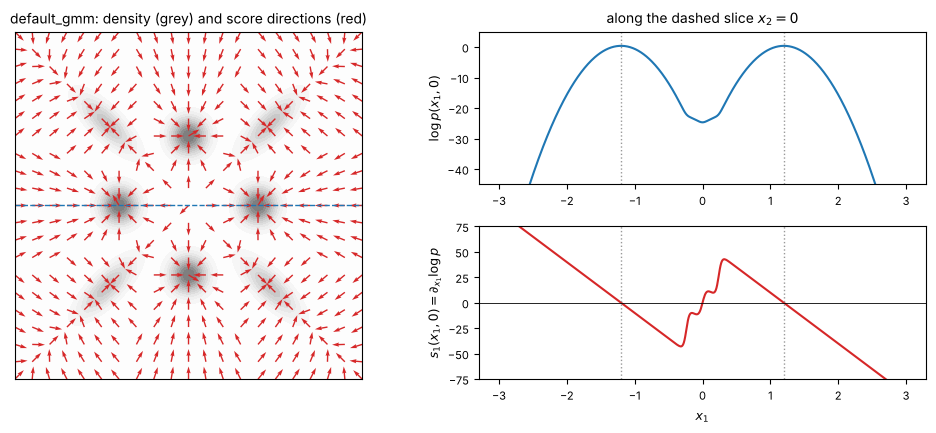

In [3]:
fig = plt.figure(figsize=(10, 4.4))
gs = fig.add_gridspec(2, 2, width_ratios=[1.05, 1.0])
ax = fig.add_subplot(gs[:, 0])
show_density(ax, gmm)
dm.plot_vector_field(lambda p: gmm_score(gmm, p).float(), ax=ax, lim=LIM, n=21, normalize=True, color=C["exact"],
                     angles="xy", scale_units="xy", scale=1 / 0.22, width=0.004)
ax.axhline(0, color="tab:blue", ls="--", lw=1)
ax.set_title("default_gmm: density (grey) and score directions (red)")

xs = torch.linspace(-LIM, LIM, 600, dtype=torch.float64)
line = torch.stack([xs, torch.zeros_like(xs)], 1)                 # the dashed slice y = 0
ax1, ax2 = fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])
ax1.plot(xs, gmm.log_prob(line), color="tab:blue")
ax1.set(ylabel=r"$\log p(x_1, 0)$", title="along the dashed slice $x_2 = 0$", ylim=(-45, 5))
ax2.plot(xs, gmm_score(gmm, line)[:, 0], color=C["exact"])
ax2.axhline(0, color="k", lw=0.6)
ax2.set(xlabel="$x_1$", ylabel=r"$s_1(x_1, 0)=\partial_{x_1}\log p$", ylim=(-75, 75))
for a in (ax1, ax2):
    for m in (-1.2, 1.2):                                          # the two inner components on this slice
        a.axvline(m, color="0.6", ls=":", lw=1)
plt.tight_layout()
plt.show()

Arrows point towards nearby high-density components. Even far from the data they point back at it, and at the centre they
point outwards, away from the density minimum there. The right-hand panels
show the 1-D picture: the score is the *slope* of $\log p$, zero at each mode (dotted lines) and also at the
density minimum between them (at $x_1=0$), and it grows linearly far from the data, where $p$ looks like the tail of a single Gaussian. The
score is steepest right next to narrow components: a narrow component means a strong pull.

## 2 · Langevin dynamics: sampling with nothing but the score

Consider the **overdamped Langevin** stochastic differential equation
$$dx = \tfrac12\nabla_x\log p(x)\,dt + dW_t .$$
Its density $\rho_t$ evolves by the Fokker–Planck equation
$\partial_t\rho = -\nabla\cdot\big(\rho\,\tfrac12\nabla\log p\big) + \tfrac12\Delta\rho$. Plug in $\rho=p$:
$-\tfrac12\nabla\cdot(p\,\nabla\log p) + \tfrac12\Delta p = -\tfrac12\nabla\cdot\nabla p + \tfrac12\Delta p = 0$.
So **$p$ is a stationary distribution**, and under mild conditions the process converges to it from any start. The drift climbs
the log-density (gradient ascent, which alone would find a mode, the MAP estimate). The noise keeps it from collapsing,
so the process explores the whole distribution.

The Euler–Maruyama discretisation with step $\delta$ gives the **unadjusted Langevin algorithm (ULA)**:
$$x_{k+1} = x_k + \frac{\delta}{2}\,s(x_k) + \sqrt{\delta}\,z_k,\qquad z_k\sim\mathcal N(0,I).$$
If you know MCMC: this is the proposal of the **Metropolis-adjusted Langevin algorithm (MALA)**. Without the accept/reject step
its stationary distribution is slightly wrong, with an $O(\delta)$ bias (for a Gaussian of variance $\sigma^2$ it is
inflated to $\sigma^2/\big(1-\delta/(4\sigma^2)\big)$; Exercise 1). With a Metropolis–Hastings correction it is exact, but MH needs
$p$ up to a constant, which a score model does not provide. Score-based samplers that take Langevin steps (NCSN in §4, and
the "corrector" steps of predictor–corrector samplers) therefore use plain ULA and keep $\delta$ small.
(Hamiltonian Monte Carlo is the momentum-augmented cousin.)

> **Gotcha: the step size is limited by the narrowest direction.** For a Gaussian with variance $\sigma^2$ the update
> multiplies the deviation from the mean by $1-\delta/(2\sigma^2)$, which diverges once $\delta>4\sigma^2$. Our mixture has
> components with variance $0.01$ along their minor axis, so $\delta$ must be well below $0.04$. We use $\delta=10^{-3}$.

In [4]:
@torch.no_grad()
def langevin(score_fn, x, step_size, n_steps, record_every=0, generator=None):
    """Unadjusted Langevin algorithm: x <- x + (step/2) * score(x) + sqrt(step) * z.

    Returns the final x, and (if record_every > 0) a (S, N, d) tensor of snapshots taken every `record_every`
    steps, starting with the initial x.
    """
    snaps = [x.clone()]
    for k in range(1, n_steps + 1):
        z = torch.randn(x.shape, dtype=x.dtype, generator=generator)
        x = x + 0.5 * step_size * score_fn(x) + math.sqrt(step_size) * z
        if record_every and k % record_every == 0:
            snaps.append(x.clone())
    return (x, torch.stack(snaps)) if record_every else x


DELTA = 1e-3
REC = 10                                                            # record a snapshot every REC steps
g = rng(0)
x_uniform = (2 * torch.rand(N_PART, 2, dtype=torch.float64, generator=g) - 1) * LIM   # far from p
x_stationary = gmm.sample(N_PART, generator=g).double()                              # exact samples of p
t0 = time.time()
x_lan, traj_lan = langevin(lambda x: gmm_score(gmm, x), x_uniform, DELTA, LANGEVIN_STEPS, REC, g)
_, traj_stat = langevin(lambda x: gmm_score(gmm, x), x_stationary, DELTA, LANGEVIN_STEPS, REC, g)
print(f"2 x {LANGEVIN_STEPS} Langevin steps on {N_PART} particles: {time.time() - t0:.1f} s")

2 x 1500 Langevin steps on 2000 particles: 4.4 s


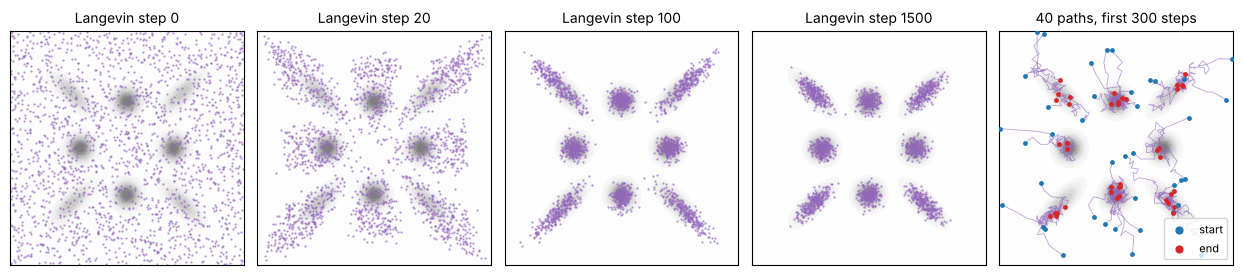

In [5]:
frames = [0, 20, 100, LANGEVIN_STEPS]
fig, axes = plt.subplots(1, len(frames) + 1, figsize=(12.5, 2.8))
for ax, it in zip(axes, frames):
    show_density(ax, gmm)
    dm.scatter2d(traj_lan[it // REC], ax=ax, s=2.5, alpha=0.7, c=C["plain"], lim=LIM, title=f"Langevin step {it}")
show_density(axes[-1], gmm)
dm.plot_trajectories(traj_lan[: 300 // REC + 1, :40], ax=axes[-1], n_show=40, lim=LIM, color=C["plain"], alpha=0.6)
axes[-1].set(title="40 paths, first 300 steps", xticks=[], yticks=[])
axes[-1].legend(loc="lower right", markerscale=2)
plt.tight_layout()
plt.show()

Particles initialised uniformly on the square are pulled into the components within about a hundred steps (the drift is
strong far from the data; compare steps 20 and 100) and then jitter around inside them. The paths on the right show the two regimes: a nearly
straight fall into the nearest basin, then a random walk confined to it.

**Does it sample the right distribution?** We measure the squared MMD (notebook 02) between the particles and fresh
samples of $p$, along the run. Two references: the MMD between two independent sets of true samples (the floor
achievable with this many points), and a chain *started at* exact samples of $p$, which should stay at the floor if $p$ is
(approximately) stationary under our discretised dynamics.

MMD floor (fresh true samples vs the reference set): 0.0089 ± 0.0028
final MMD, uniform start: 0.0895 | stationary start: 0.0129 | uniform start after re-weighting the components: 0.0078


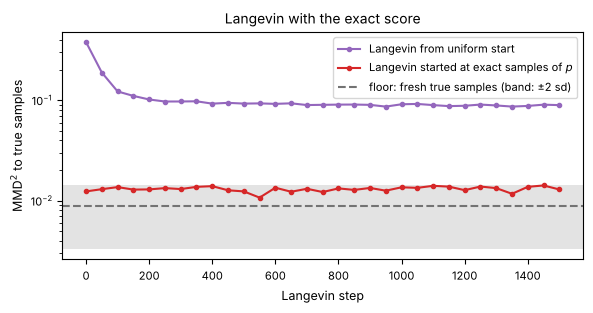

In [6]:
MMD_N = 1000                                                        # points per MMD evaluation (cost ~ MMD_N^2)
g = rng(1)
x_ref = gmm.sample(N_PART, generator=g)                             # the reference set every curve is compared with
# floor: fresh exact samples vs the same reference set, repeated to see how much the metric fluctuates
floor_runs = np.array([dm.mmd_rbf(gmm.sample(MMD_N, generator=g), x_ref, max_n=MMD_N) for _ in range(30)])
floor, floor_sd = floor_runs.mean(), floor_runs.std()
idx = np.arange(0, len(traj_lan), 5)                                # every 5th snapshot = every 50 steps
mmd_uniform = [dm.mmd_rbf(traj_lan[i], x_ref, max_n=MMD_N) for i in idx]
mmd_stat = [dm.mmd_rbf(traj_stat[i], x_ref, max_n=MMD_N) for i in idx]

# Which component did each particle end up in? Compare the occupation fractions with the mixture weights.
comp_lan = gmm.responsibilities(x_lan).argmax(1)
frac_lan = torch.bincount(comp_lan, minlength=gmm.K).double() / N_PART
# Re-weight: resample particles so each component gets its true weight. If the MMD then drops to the floor,
# the particles have the right shape *within* each component and only the proportions are wrong.
particle_w = (gmm.weights / frac_lan.clamp(min=1e-12))[comp_lan]
resampled = x_lan[torch.multinomial(particle_w, N_PART, replacement=True, generator=g)]
mmd_resampled = dm.mmd_rbf(resampled, x_ref, max_n=MMD_N)
print(f"MMD floor (fresh true samples vs the reference set): {floor:.4f} ± {floor_sd:.4f}")
print(f"final MMD, uniform start: {mmd_uniform[-1]:.4f} | stationary start: {mmd_stat[-1]:.4f} | "
      f"uniform start after re-weighting the components: {mmd_resampled:.4f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(idx * REC, mmd_uniform, color=C["plain"], marker="o", ms=3, label="Langevin from uniform start")
ax.plot(idx * REC, mmd_stat, color=C["exact"], marker="o", ms=3, label="Langevin started at exact samples of $p$")
ax.axhline(floor, color=C["data"], ls="--", label="floor: fresh true samples (band: ±2 sd)")
ax.axhspan(max(floor - 2 * floor_sd, 1e-4), floor + 2 * floor_sd, color=C["data"], alpha=0.2, lw=0)
ax.set(yscale="log", xlabel="Langevin step", ylabel="MMD$^2$ to true samples", title="Langevin with the exact score")
ax.legend()
plt.tight_layout()
plt.show()

Two things are true at once. The chain started at $p$ begins at a value typical of exact samples (its first point *is* a set
of exact samples, so its distance from the dashed line is just the metric's sampling noise) and does not drift away, so $p$ is
indeed (up to the small ULA bias) a fixed point of the dynamics. The chain started from the uniform square improves quickly and then **stalls** well above the
floor. The printed re-weighting experiment locates the problem. Once we fix only the *proportions* of particles per
component, the MMD drops to about the floor. So Langevin got the shape of every component right, but put the wrong
number of particles into each. That is the first failure mode of plain Langevin.

## 3 · Two failure modes of plain Langevin (Song & Ermon 2019)

### 3a · Wrong mode weights when modes are separated by low-density regions

Suppose $p = \pi\,p_1 + (1-\pi)\,p_2$ with $p_1, p_2$ (essentially) disjoint. On the support of $p_1$,
$$\nabla\log p(x) = \nabla\log\big(\pi\,p_1(x)\big) = \nabla\log p_1(x),$$
because $\log\pi$ is a constant. **Near the modes, the score does not contain the mixture weight.** A Langevin chain can only learn
about $\pi$ by travelling between the modes, and the time that takes grows exponentially with the depth of the low-density
valley. In practice the proportions are frozen at whatever the *initialisation* put into each basin of attraction.

(Strictly, a mixture with full support, like ours, *does* encode its weights in the score, but only through the score's
values inside the valley, as §1 said. In the example below, the weights 0.8/0.2 move the density minimum between the
modes from $x_1=0$ to $x_1\approx0.025$, where the density is about $e^{-35}$ times its peak. Langevin essentially never
goes there, and a learned score is least accurate there (3b). So this is a mixing-time problem, not an information
problem, but in practice the information is lost either way.)

The next figure compares that two-mode example with a mixture of the same two modes in equal proportions.

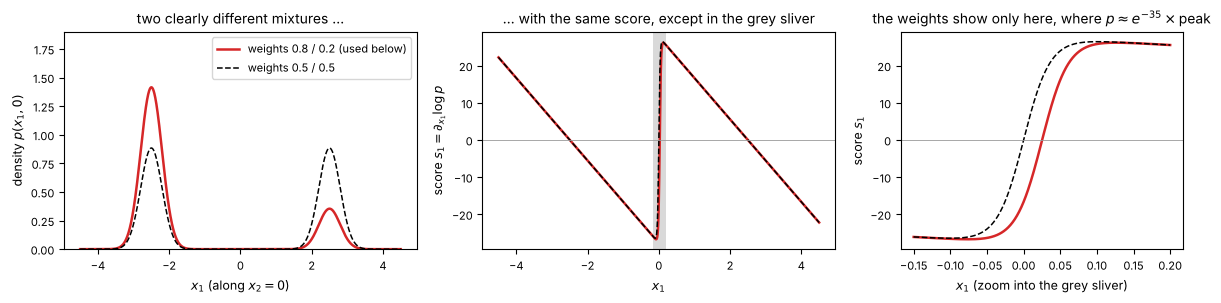

the two scores differ by more than 0.1 only for -0.10 < x1 < 0.13, where p is at most e^-32 times its peak


In [7]:
# Same two modes, different weights: the 0.8 / 0.2 mixture used below vs equal weights, along the slice x_2 = 0
viz_x1 = torch.linspace(-4.5, 4.5, 1801, dtype=torch.float64)
viz_line = torch.stack([viz_x1, torch.zeros_like(viz_x1)], 1)
viz_zoom = torch.linspace(-0.15, 0.2, 351, dtype=torch.float64)                    # around the density minimum
viz_zline = torch.stack([viz_zoom, torch.zeros_like(viz_zoom)], 1)
viz_logp, viz_score = {}, {}
viz_fig, viz_axes = plt.subplots(1, 3, figsize=(12, 3.1), gridspec_kw={"width_ratios": [1, 1, 0.8]})
for viz_w, viz_lab, viz_style in [(0.8, "weights 0.8 / 0.2 (used below)", dict(color=C["exact"], lw=1.8)),
                                  (0.5, "weights 0.5 / 0.5", dict(color="k", lw=1.1, ls="--"))]:
    viz_mix = dm.GaussianMixture([viz_w, 1 - viz_w], [[-2.5, 0.0], [2.5, 0.0]], [0.09, 0.09])
    viz_logp[viz_w] = torch.logsumexp(viz_mix.component_log_probs(viz_line), 1)      # float64 log-density
    viz_score[viz_w] = gmm_score(viz_mix, viz_line)[:, 0]
    viz_axes[0].plot(viz_x1, viz_logp[viz_w].exp(), label=viz_lab, **viz_style)
    viz_axes[1].plot(viz_x1, viz_score[viz_w], **viz_style)
    viz_axes[2].plot(viz_zoom, gmm_score(viz_mix, viz_zline)[:, 0], **viz_style)
viz_rel = viz_logp[0.8] - viz_logp[0.8].max()                   # log(p / peak) of the 0.8 / 0.2 mixture
viz_depth = viz_rel[viz_x1.abs() < 1].min().item()              # ... at its density minimum between the modes
viz_differ = (viz_score[0.8] - viz_score[0.5]).abs() > 0.1      # where the two scores differ noticeably
viz_axes[0].set(xlabel="$x_1$ (along $x_2 = 0$)", ylabel="density $p(x_1, 0)$", ylim=(0, 1.9),
                title="two clearly different mixtures ...")
viz_axes[0].legend(loc="upper right")
viz_axes[1].axvspan(viz_zoom[0].item(), viz_zoom[-1].item(), color="0.85", lw=0)
viz_axes[1].axhline(0, color="0.6", lw=0.6)
viz_axes[1].set(xlabel="$x_1$", ylabel=r"score $s_1=\partial_{x_1}\log p$",
                title="... with the same score, except in the grey sliver")
viz_axes[2].axhline(0, color="0.6", lw=0.6)
viz_axes[2].set(xlabel="$x_1$ (zoom into the grey sliver)", ylabel=r"score $s_1$",
                title=rf"the weights show only here, where $p\approx e^{{{viz_depth:.0f}}}\times$peak")
plt.tight_layout()
plt.show()
print(f"the two scores differ by more than 0.1 only for {viz_x1[viz_differ].min():.2f} < x1 < "
      f"{viz_x1[viz_differ].max():.2f}, where p is at most e^{viz_rel[viz_differ].max():.0f} times its peak")

The two densities differ visibly (left), yet their scores lie on top of each other (middle): near each mode the weight
only adds a constant to $\log p$, which the gradient removes. All the weights change is where the score jumps through
zero (the density minimum): from $x_1=0$ to about $0.025$ (right), inside a sliver where $p$ is at most about $e^{-32}$
times its peak (printed). A sampler that follows the score near the modes cannot tell that the left mode is four times
heavier.

The 8-component mixture above already shows this: the left panel below gives its per-component occupation, the
cause of the stalled MMD in §2. The other two panels show a cleaner version: two well-separated modes with weights
0.8 and 0.2, and particles started uniformly on a square.

fraction of particles in the heavy mode after 1500 steps: 0.520 (truth 0.8)


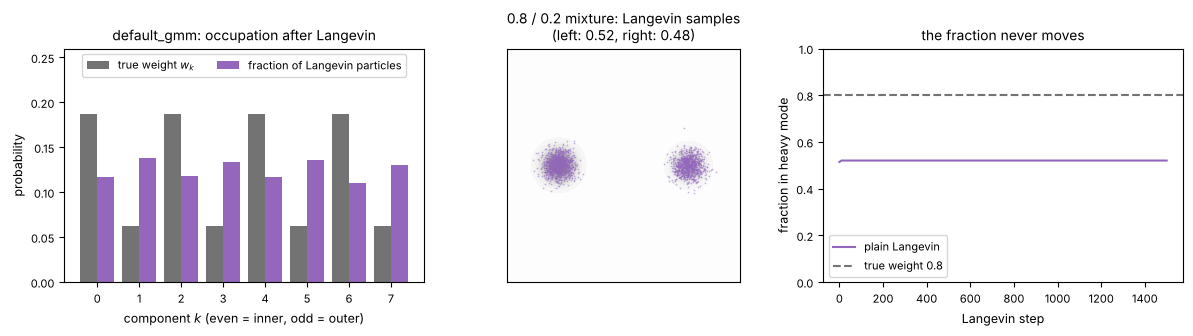

In [8]:
two = dm.GaussianMixture([0.8, 0.2], [[-2.5, 0.0], [2.5, 0.0]], [0.09, 0.09])   # std 0.3, 16 std apart
LIM2 = 4.5
g = rng(3)
x0_two = (2 * torch.rand(N_PART, 2, dtype=torch.float64, generator=g) - 1) * 4.0   # uniform start, reused in §4
x_plain, traj_plain = langevin(lambda x: gmm_score(two, x), x0_two, 1e-2, LANGEVIN_STEPS, REC, g)
heavy_plain = (traj_plain[:, :, 0] < 0).double().mean(1)            # fraction in the heavy (left) mode
print(f"fraction of particles in the heavy mode after {LANGEVIN_STEPS} steps: {heavy_plain[-1]:.3f} (truth 0.8)")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), gridspec_kw={"width_ratios": [1.3, 1, 1.3]})
k = np.arange(gmm.K)
axes[0].bar(k - 0.2, gmm.weights.numpy(), 0.4, color=C["data"], label="true weight $w_k$")
axes[0].bar(k + 0.2, frac_lan.numpy(), 0.4, color=C["plain"], label="fraction of Langevin particles")
axes[0].set(xlabel="component $k$ (even = inner, odd = outer)", ylabel="probability", xticks=k, ylim=(0, 0.26),
            title="default_gmm: occupation after Langevin")
axes[0].legend(loc="upper center", ncol=2)
show_density(axes[1], two, lim=LIM2)
dm.scatter2d(x_plain, ax=axes[1], s=1.5, alpha=0.5, c=C["plain"], lim=LIM2,
             title=f"0.8 / 0.2 mixture: Langevin samples\n(left: {heavy_plain[-1]:.2f}, right: {1 - heavy_plain[-1]:.2f})")
axes[2].plot(np.arange(len(heavy_plain)) * REC, heavy_plain, color=C["plain"], label="plain Langevin")
axes[2].axhline(0.8, color=C["data"], ls="--", label="true weight 0.8")
axes[2].set(xlabel="Langevin step", ylabel="fraction in heavy mode", ylim=(0, 1), title="the fraction never moves")
axes[2].legend()
plt.tight_layout()
plt.show()

In the 8-component mixture (left), the light outer components end up over-populated, at roughly twice their weight: they sit further out, so a
uniform start puts more particles into their basins than their weight warrants. In the two-mode example the fraction
is fixed by the geometry of the start (about half the square lies on each side) and stays there for the whole run.
Each mode is sampled perfectly well internally. The chain simply never discovers that one mode is four times heavier.

### 3b · Scores are poorly estimated in low-density regions

The second failure mode only appears once the score is *learned*. Any score-matching objective (§5) is an expectation
under the data, $\mathbb E_{x\sim p}\|s_\theta(x)-\nabla\log p(x)\|^2$, so it says nothing about $s_\theta$ where $p$ is tiny.
With a finite training set the network sees no examples at all in most of the space. But Langevin chains *start*
exactly there (in noise, or anywhere we initialise them) and must be guided home by the score in that unconstrained
territory. The training set we will use in §7 shows how empty the space is:

In [9]:
train_data = gmm.sample(N_TRAIN, generator=torch.Generator().manual_seed(0))   # training set for §7
counts, _, _ = np.histogram2d(train_data[:, 0].numpy(), train_data[:, 1].numpy(), bins=60,
                              range=[[-LIM, LIM], [-LIM, LIM]])
print(f"{N_TRAIN} training points, [-{LIM:.0f}, {LIM:.0f}]^2 split into 60 x 60 cells: "
      f"{(counts == 0).mean():.0%} of the cells contain no training point, {(counts < 10).mean():.0%} contain fewer than 10")

20000 training points, [-3, 3]^2 split into 60 x 60 cells: 81% of the cells contain no training point, 91% contain fewer than 10


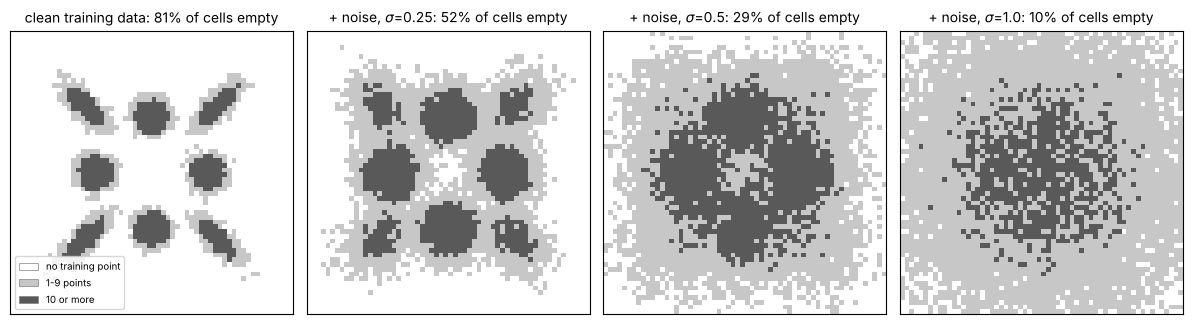

In [10]:
# The same 60 x 60 cells, shaded by how many training points each holds. The last three panels preview §4: every
# training point plus Gaussian noise of standard deviation sigma (the same noise draw, scaled).
viz_edges = np.linspace(-LIM, LIM, 61)
viz_shades = ["white", "0.78", "0.35"]                                    # no point / 1-9 points / 10 or more
viz_panels = [("clean training data", counts)]
for viz_s in [0.25, 0.5, 1.0]:
    viz_noisy = train_data.double() + viz_s * torch.randn(train_data.shape, dtype=torch.float64, generator=rng(20))
    viz_panels.append((rf"+ noise, $\sigma$={viz_s}",
                       np.histogram2d(viz_noisy[:, 0].numpy(), viz_noisy[:, 1].numpy(), bins=60,
                                      range=[[-LIM, LIM], [-LIM, LIM]])[0]))
viz_fig, viz_axes = plt.subplots(1, len(viz_panels), figsize=(12, 3.4))
for viz_ax, (viz_title, viz_cnt) in zip(viz_axes, viz_panels):
    viz_ax.pcolormesh(viz_edges, viz_edges, np.digitize(viz_cnt.T, [1, 10]), cmap=ListedColormap(viz_shades),
                      vmin=0, vmax=2)
    viz_ax.set(aspect="equal", xticks=[], yticks=[], title=f"{viz_title}: {(viz_cnt == 0).mean():.0%} of cells empty")
viz_axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=c, ec="0.5", lw=0.5) for c in viz_shades],
                   labels=["no training point", "1-9 points", "10 or more"], loc="lower left", fontsize=7)
plt.tight_layout()
plt.show()

In the left panel, every white cell received none of the 20,000 training points: the data occupy a few small islands.
The other panels preview the cure of §4. Add Gaussian noise of standard deviation $\sigma$ to every point, and the same
points spread over the square (at $\sigma=1$ only about a tenth of the cells, mostly near the edges, stay empty).

Most of the square never receives a training signal. In §7 we will measure exactly how wrong a trained network's
score is there. Both failure modes have the same cure, which is the central idea of score-based diffusion models.

## 4 · The fix: anneal through noise levels

Add Gaussian noise to the data: $q_\sigma = p \ast \mathcal N(0,\sigma^2I)$, the "variance exploding" marginal of
notebook 01 (`dm.GaussianMixture.noised_ve(sigma)` gives it exactly). For large $\sigma$:
- **the modes are connected**: $q_\sigma$ has no deep valleys, so Langevin mixes quickly and particles can redistribute;
- **there are no low-density holes**: noised training points fill the whole space, so a learned score is constrained everywhere
  (the right-hand panels of the figure in §3b).

And for every $\sigma>0$:
- **the score exists everywhere**: real data such as images concentrate near low-dimensional manifolds, off which $p=0$
  and $\nabla\log p$ is undefined, so score matching on clean data is ill-posed. $q_\sigma$ has full support, so its score is
  always well defined (Song & Ermon 2019, §3.1; our 2-D mixtures have full support and never show this problem).

For small $\sigma$, $q_\sigma\approx p$. **Annealed Langevin dynamics** (Song & Ermon 2019, Alg. 1) runs a few
Langevin steps at each of a decreasing sequence $\sigma_1>\sigma_2>\dots>\sigma_L$, each level starting from where the
previous one ended, with step size $\alpha_i = \eta\,\sigma_i^2$.

**Why noise rather than temperature?** An MCMC practitioner's first instinct for a multimodal target is tempering:
sample $p^\beta$ with $\beta<1$. Tempering flattens the barriers but also changes the *weights*, since the mass ratio of two equal-shaped
modes becomes $(\pi/(1-\pi))^\beta\to1$. Convolution with noise flattens the barriers and **keeps each component's
mass**: $q_\sigma=\sum_k w_k\,(p_k\ast\mathcal N(0,\sigma^2 I))$, with every $w_k$ unchanged. Particles that keep
equilibrating as $\sigma$ shrinks track the mass of $q_\sigma$ on each side of the valley. That mass approaches the true
weights as the components separate, and the split *freezes* at the last level where particles can still cross the valley
(here around $\sigma\approx1$; Exercise 2c). The noise ladder therefore needs levels in that range.

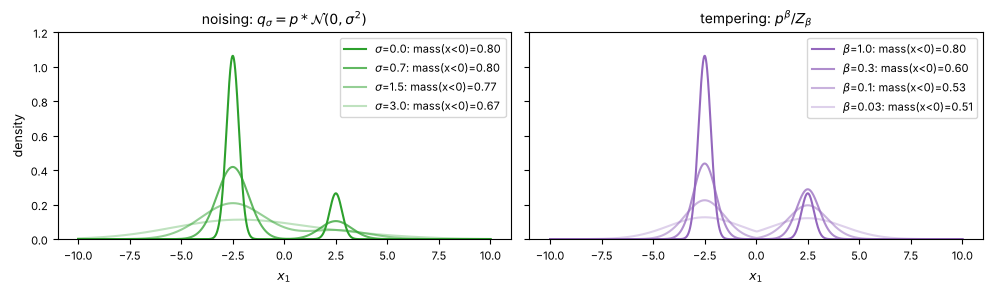

In [11]:
def x_marginal(g):
    """1-D marginal of a 2-D dm.GaussianMixture along the first coordinate (again a GMM)."""
    return dm.GaussianMixture(g.weights, g.means[:, :1], g.covs[:, :1, :1])


u = torch.linspace(-10, 10, 2001, dtype=torch.float64)[:, None]
du = (u[1] - u[0]).item()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.0), sharey=True)
for sigma, shade in zip([0.0, 0.7, 1.5, 3.0], [1.0, 0.75, 0.5, 0.3]):
    dens = x_marginal(two.noised_ve(sigma)).log_prob(u).exp()
    left = (dens[u[:, 0] < 0].sum() * du).item()
    axes[0].plot(u, dens, color=C["annealed"], alpha=shade, label=rf"$\sigma$={sigma}: mass(x<0)={left:.2f}")
log_p1 = x_marginal(two).log_prob(u).double()
for beta, shade in zip([1.0, 0.3, 0.1, 0.03], [1.0, 0.75, 0.5, 0.3]):
    dens = torch.softmax(beta * log_p1, 0) / du                      # p^beta, normalised on the grid
    left = (dens[u[:, 0] < 0].sum() * du).item()
    axes[1].plot(u, dens, color=C["plain"], alpha=shade, label=rf"$\beta$={beta}: mass(x<0)={left:.2f}")
axes[0].set(title=r"noising: $q_\sigma = p * \mathcal{N}(0,\sigma^2)$", xlabel="$x_1$", ylabel="density", ylim=(0, 1.2))
axes[1].set(title=r"tempering: $p^\beta / Z_\beta$", xlabel="$x_1$")
for a in axes:
    a.legend(loc="upper right")
plt.tight_layout()
plt.show()

Both families eventually connect the two modes. Under noising each *component* keeps exactly its weight; the mass left of
$x_1=0$ (legend) drops at large $\sigma$ only because the widened heavy bump spills across the midline. Tempering instead moves
weight between the modes, driving the split towards 50/50 even where the bumps barely overlap, so a tempered chain would have to be
corrected (as in parallel tempering) to recover the weights. Now the annealed sampler, with the same total number of steps as the plain run of §3a:

> **Gotcha: the step size must scale with the noise level.** With $\alpha_i=\eta\sigma_i^2$, the drift
> $\tfrac{\alpha}{2}\nabla\log q_\sigma\sim\eta\,\sigma/2$ and the noise $\sqrt{\alpha}=\sqrt\eta\,\sigma$ keep a fixed ratio at
> every level (Song & Ermon's choice). But when $\sigma$ falls below the data's own width the steps become too small to
> move particles within a component in the allotted steps. A too-small $\eta$ then "freezes" the particles at an
> earlier, wider level. We use $\eta=0.2$.

In [12]:
@torch.no_grad()
def annealed_langevin(score_fn, x, sigmas, n_per_level, eta, record_every=0, generator=None):
    """Annealed Langevin dynamics (Song & Ermon 2019, Alg. 1): plain Langevin at each noise level, largest first.

    score_fn(x, sigma) is the score of the sigma-noised data; the step size at level sigma is eta * sigma^2.
    Returns the final x, the snapshots of the whole run, and the particles at the end of every level.
    """
    snaps, level_ends = [x.clone()], []
    for sigma in sigmas:
        x, tr = langevin(lambda y: score_fn(y, sigma), x, eta * sigma ** 2, n_per_level,
                         record_every or n_per_level, generator)
        snaps += list(tr[1:])
        level_ends.append(x.clone())
    return x, torch.stack(snaps), level_ends


sigmas = np.geomspace(5.0, 0.05, N_LEVELS)          # sigma_max ~ distance between the modes (Song & Ermon 2020)
noised_two = {s: two.noised_ve(s) for s in sigmas}  # exact noised mixtures, precomputed once
x_ann, traj_ann, level_ends = annealed_langevin(lambda x, s: gmm_score(noised_two[s], x), x0_two, sigmas,
                                                PER_LEVEL, eta=0.2, record_every=REC, generator=rng(4))
heavy_ann = (traj_ann[:, :, 0] < 0).double().mean(1)
se = math.sqrt(0.8 * 0.2 / N_PART)                  # binomial standard error of a fraction estimated from N_PART particles
print(f"fraction in heavy mode: annealed {heavy_ann[-1]:.3f}, plain {heavy_plain[-1]:.3f}, truth 0.8 "
      f"(Monte Carlo standard error {se:.3f}; annealed is {(heavy_ann[-1] - 0.8) / se:+.1f} SE from the truth)")
in_heavy = x_ann[x_ann[:, 0] < 0]
print(f"std of the annealed particles inside the heavy mode: {in_heavy.std(0).numpy().round(3)} (truth 0.3)")

fraction in heavy mode: annealed 0.785, plain 0.520, truth 0.8 (Monte Carlo standard error 0.009; annealed is -1.7 SE from the truth)
std of the annealed particles inside the heavy mode: [0.308 0.3  ] (truth 0.3)


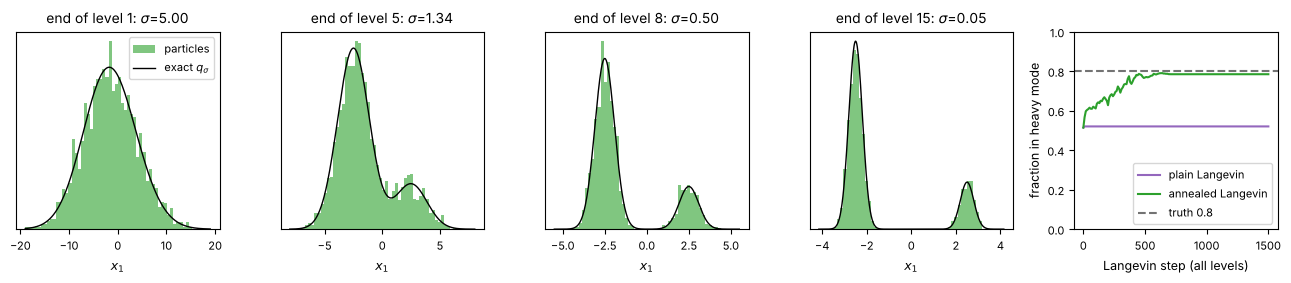

In [13]:
show_levels = [0, 4, 7, N_LEVELS - 1]
fig, axes = plt.subplots(1, len(show_levels) + 1, figsize=(13, 2.9))
for ax, i in zip(axes, show_levels):
    s = sigmas[i]
    lim = 4.0 + 3 * s
    grid = torch.linspace(-lim, lim, 400, dtype=torch.float64)[:, None]
    ax.hist(level_ends[i][:, 0].numpy(), bins=60, range=(-lim, lim), density=True, color=C["annealed"], alpha=0.6,
            label="particles")
    ax.plot(grid, x_marginal(noised_two[s]).log_prob(grid).exp(), color="k", lw=1, label=r"exact $q_\sigma$")
    ax.set(title=rf"end of level {i + 1}: $\sigma$={s:.2f}", xlabel="$x_1$", yticks=[])
axes[0].legend(loc="upper right")
t_steps = np.arange(len(heavy_ann)) * REC
axes[-1].plot(t_steps, heavy_plain, color=C["plain"], label="plain Langevin")
axes[-1].plot(t_steps, heavy_ann, color=C["annealed"], label="annealed Langevin")
axes[-1].axhline(0.8, color=C["data"], ls="--", label="truth 0.8")
axes[-1].set(xlabel="Langevin step (all levels)", ylabel="fraction in heavy mode", ylim=(0, 1))
axes[-1].legend(loc="lower right")
plt.tight_layout()
plt.show()

At $\sigma=5$ the noised distribution is a single broad bump and the particles fill it. As $\sigma$ shrinks the bump splits,
and the particles split with it in proportion to the mass on each side. At every level the histogram follows the exact
$q_\sigma$ (black). The heavy-mode fraction (right) climbs during the first, high-noise levels, as the mass of $q_\sigma$ left of
the valley grows, and freezes once the modes separate. The printed number is within a few Monte Carlo standard errors of 0.8.

**How this relates to a diffusion model's reverse process.** The coarse-to-fine path is the same: start from broad noise,
follow the scores of progressively less noisy versions of the data, end at the data. The mechanism differs.
- Annealed Langevin is **MCMC**: every step leaves the current $q_\sigma$ invariant, so samples only move to the next level
  by *re-equilibrating* (hence the many steps per level).
- DDPM's ancestral sampler (notebook 02) discretises a **reverse-time SDE** (Anderson 1982; Song et al. 2021) that carries
  samples of $q_t$ to samples of $q_{t-1}$ in *one* step, without equilibrating. Its score drift is twice that of a Langevin step
  with the same injected noise. Half of it *transports* mass (the deterministic probability-flow ODE of notebook 04), and the
  other half is a Langevin-type correction.

In Song et al.'s predictor–corrector language, annealed Langevin is a "corrector-only" sampler and DDPM a "predictor-only" one,
and the two can be combined. (The noise processes differ too: NCSN's $x_0+\sigma\epsilon$ corresponds to the variance-exploding SDE,
DDPM to the variance-preserving one.) VE and VP noising are related by a rescaling (notebook 01, §9):
$x_t/\sqrt{\bar\alpha_t}=x_0+\sigma_t\,\epsilon$ with $\sigma_t=\sqrt{(1-\bar\alpha_t)/\bar\alpha_t}$, so
$q^\text{VP}_t(x)\propto q^\text{VE}_{\sigma_t}(x/\sqrt{\bar\alpha_t})$ and
$\nabla\log q^\text{VP}_t(x)=\nabla\log q^\text{VE}_{\sigma_t}(x/\sqrt{\bar\alpha_t})\,/\sqrt{\bar\alpha_t}$.
The next cell checks this and places our $\sigma$ ladder on DDPM's time axis. From here on we use DDPM's (VP) notation.
(As in `dmtools`, the $t$ in code, printouts and plot titles is the array index $0,\dots,T-1$, one less than the maths'
$t$: `ABAR[t]` is $\bar\alpha_{t+1}$; notebook 02, §1.)

*Side note — safe to skim: checks that the VP score is the rescaled VE score and maps our $\sigma$ ladder onto DDPM's timesteps (the figure after it puts both on one noise axis); rule to remember: the code's `t` is the array index, so `ABAR[t]` is the maths' $\bar\alpha_{t+1}$.*

In [14]:
sched = dm.NoiseSchedule(1000, "linear", device=device)   # DDPM's linear schedule, T = 1000, used from here on
ABAR = sched.alpha_bars.cpu().double()                      # float64 copy for exact computations (.cpu() first: MPS)
SIGMA_T = ((1 - ABAR) / ABAR).sqrt()                        # the VE noise level equivalent to each VP timestep

# CHECK: the VP score is the rescaled VE score at the matched noise level
xq = 2.0 * torch.randn(500, 2, dtype=torch.float64, generator=rng(5))
for t in [10, 200, 700]:
    a = ABAR[t].item()
    vp = gmm_score(gmm.noised(a), xq)
    ve = gmm_score(gmm.noised_ve(SIGMA_T[t].item()), xq / math.sqrt(a)) / math.sqrt(a)
    assert torch.allclose(vp, ve, rtol=1e-8, atol=1e-8)
print("grad log q_t^VP(x) == grad log q_sigma_t^VE(x / sqrt(abar_t)) / sqrt(abar_t)  ✓")
for s in [sigmas[0], sigmas[len(sigmas) // 2], sigmas[-1]]:
    print(f"annealing level sigma = {s:5.2f}  <->  DDPM timestep t ≈ {int((SIGMA_T - s).abs().argmin())}")
print(f"DDPM's own range: sigma_t from {SIGMA_T[0]:.3f} (t=0) to {SIGMA_T[-1]:.0f} (t={sched.T - 1})")

grad log q_t^VP(x) == grad log q_sigma_t^VE(x / sqrt(abar_t)) / sqrt(abar_t)  ✓
annealing level sigma =  5.00  <->  DDPM timestep t ≈ 565
annealing level sigma =  0.50  <->  DDPM timestep t ≈ 144
annealing level sigma =  0.05  <->  DDPM timestep t ≈ 11
DDPM's own range: sigma_t from 0.010 (t=0) to 157 (t=999)


Our hand-made ladder covers only the middle of DDPM's range. DDPM starts from far more noise (at its last index $t=T-1$,
$\sigma_t\approx157$, so $x_t$ itself is essentially pure $\mathcal N(0,I)$) and ends at a smaller $\sigma$.

Exact scores make the difference between re-equilibrating and transporting easy to see. We hand the exact score of the
two-mode mixture, as a noise prediction $\epsilon^*=-\sqrt{1-\bar\alpha_t}\,\nabla\log q_t$, to the unchanged
`dm.ddpm_sample` (§8 does the same for the 8-component mixture), and follow the fraction of particles on the heavy side
of the valley as the noise level falls, for DDPM and for the annealed Langevin run above. DDPM gets five times as many
particles, so that its dots show its average behaviour with little sampling noise.

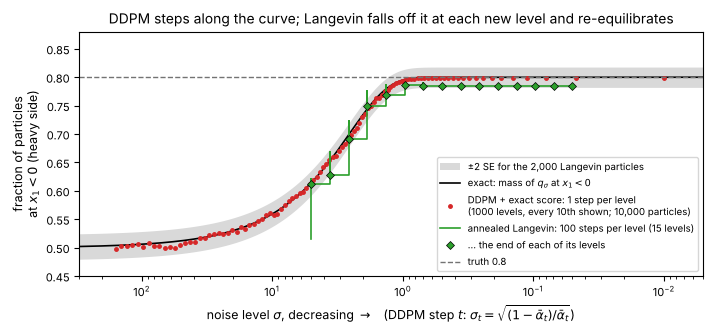

DDPM particles vs the exact marginal at 101 recorded steps: deviation median 0.4 SE, largest 2.2 SE (SE for 10,000 particles)


In [15]:
viz_s1a = (1 - ABAR).sqrt()


def viz_two_eps(x, t, y=None):
    """Exact noise prediction for `two`: -sqrt(1 - abar_t) * grad log q_t(x). Samplers pass one t per batch."""
    tv = int(t[0])
    return (-viz_s1a[tv] * gmm_score(two.noised(ABAR[tv].item()), x.cpu())).to(x.device, x.dtype)


def viz_mass_left(sig):
    """Exact mass of the sigma-noised two-mode mixture on the heavy side of the valley, x_1 < 0."""
    sig = torch.as_tensor(sig, dtype=torch.float64)
    return sum(w * torch.special.ndtr(-m / (v + sig ** 2).sqrt())
               for w, m, v in zip(two.weights, two.means[:, 0], two.covs[:, 0, 0])).numpy()


viz_n_ddpm = 5 * N_PART                      # 5x the Langevin particles, so that DDPM's dots carry little sampling noise
viz_x_ddpm, viz_traj = dm.ddpm_sample(viz_two_eps, sched, (viz_n_ddpm, 2), return_traj=True, traj_every=10,
                                      generator=torch.Generator(device=device).manual_seed(21))
viz_ddpm_sig = np.array([SIGMA_T[t].item() for t, _, _ in viz_traj])     # the VE noise level matching each x_t
viz_ddpm_frac = np.array([(xt[:, 0] < 0).double().mean().item() for _, xt, _ in viz_traj])  # sign is scale-free
# The whole annealed Langevin run above (a snapshot every REC steps) as a path in the same plane: at each level a
# vertical segment (sigma fixed while the split changes), joined to the next level by a horizontal move.
viz_per = (len(heavy_ann) - 1) // N_LEVELS                                 # snapshots per level
viz_lan_sig = np.repeat(sigmas, viz_per + 1)
viz_lan_frac = np.concatenate([heavy_ann[i * viz_per:(i + 1) * viz_per + 1].numpy() for i in range(N_LEVELS)])
viz_sig = np.geomspace(0.005, 300, 400)
viz_band = 2 * np.sqrt(viz_mass_left(viz_sig) * (1 - viz_mass_left(viz_sig)) / N_PART)   # ±2 binomial SE

viz_fig, viz_ax = plt.subplots(figsize=(7.2, 3.4))
viz_ax.fill_between(viz_sig, viz_mass_left(viz_sig) - viz_band, viz_mass_left(viz_sig) + viz_band, color="0.85", lw=0,
                    label=f"±2 SE for the {N_PART:,} Langevin particles")
viz_ax.plot(viz_sig, viz_mass_left(viz_sig), color="k", lw=1.2, label=r"exact: mass of $q_\sigma$ at $x_1<0$")
viz_ax.plot(viz_ddpm_sig, viz_ddpm_frac, "o", ms=2.5, color=C["exact"],
            label=f"DDPM + exact score: 1 step per level\n({sched.T} levels, every 10th shown; {viz_n_ddpm:,} particles)")
viz_ax.plot(viz_lan_sig, viz_lan_frac, color=C["annealed"], lw=1.2,
            label=f"annealed Langevin: {PER_LEVEL} steps per level ({N_LEVELS} levels)")
viz_ax.plot(sigmas, [(x[:, 0] < 0).double().mean().item() for x in level_ends], "D", ms=4.5, color=C["annealed"],
            mec="k", mew=0.5, label="... the end of each of its levels")
viz_ax.axhline(0.8, color=C["data"], ls="--", lw=1, label="truth 0.8")
viz_ax.set(xscale="log", xlim=(300, 0.005), ylim=(0.45, 0.88), ylabel="fraction of particles\nat $x_1<0$ (heavy side)",
           xlabel=r"noise level $\sigma$, decreasing $\rightarrow$   "
                  r"(DDPM step $t$: $\sigma_t=\sqrt{(1-\bar\alpha_t)/\bar\alpha_t}$)",
           title="DDPM steps along the curve; Langevin falls off it at each new level and re-equilibrates")
viz_ax.legend(loc="lower right", fontsize=7)
plt.tight_layout()
plt.show()
viz_dev = np.abs(viz_ddpm_frac - viz_mass_left(viz_ddpm_sig)) / np.sqrt(
    viz_mass_left(viz_ddpm_sig) * (1 - viz_mass_left(viz_ddpm_sig)) / viz_n_ddpm)
print(f"DDPM particles vs the exact marginal at {len(viz_dev)} recorded steps: deviation median {np.median(viz_dev):.1f} SE, "
      f"largest {viz_dev.max():.1f} SE (SE for {viz_n_ddpm:,} particles)")

The black curve is where the particles should be at each noise level: the mass of $q_\sigma$ on the heavy side. Each red
dot shows DDPM's particles at one of its noise levels, reached with a *single* step from the level before, and the dots
stay on the curve all the way down: one step carries the particles from one noise level to the next. The green staircase
is annealed Langevin. Each drop to the next level (a horizontal segment) leaves its particles with the previous level's
split, below the curve, and the 100 MCMC steps at the new level re-equilibrate them, climbing back towards the curve (a
vertical segment; diamonds mark the level ends). Once the modes separate ($\sigma\lesssim1$) the split freezes, here
slightly below the curve but within the band. What remains is to *learn* the noised scores from data.

## 5 · Learning the score: from explicit to denoising score matching

**Explicit score matching** would minimise the distance to the true score,
$$J_\text{ESM}(s) = \mathbb E_{x\sim p}\,\|s(x)-\nabla\log p(x)\|^2,$$
which needs the unknown $\nabla\log p$. Hyvärinen (2005) expanded the square and integrated the cross term by parts,
$\mathbb E_p[s\cdot\nabla\log p]=\int s\cdot\nabla p\,dx=-\int p\,\nabla\cdot s\,dx$ (assuming $p\,s\to0$ at infinity), to get
the equivalent **implicit score matching** objective
$$J_\text{ISM}(s) = \mathbb E_{x\sim p}\Big[2\operatorname{tr}\big(\nabla_x s(x)\big)+\|s(x)\|^2\Big] = J_\text{ESM}(s)-\mathbb E_p\|\nabla\log p\|^2 .$$
(Papers usually carry an overall factor $\tfrac12$; we drop it everywhere so that the identities below need no factors of 2.)
This is tractable in principle, but the trace of the Jacobian costs one backward pass *per input dimension* (784 for MNIST,
about 200k for a 256×256 RGB image). It also only constrains $s_\theta$ where the data are (failure mode 3b).
(Sliced score matching replaces the trace by random projections; we will not need it.)

**Denoising score matching** (Vincent 2011) sidesteps both problems by learning the score of the *noised* distribution.
With the forward process of notebook 01,
$x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$, the conditional density $q(x_t\mid x_0)$ is Gaussian and its score is known:
$$\nabla_{x_t}\log q(x_t\mid x_0) = -\frac{x_t-\sqrt{\bar\alpha_t}\,x_0}{1-\bar\alpha_t} = -\frac{\epsilon}{\sqrt{1-\bar\alpha_t}} .$$

**The key identity: the marginal score is the posterior average of the conditional scores.** With
$q_t(x_t)=\int q(x_t\mid x_0)\,p(x_0)\,dx_0$,
$$\nabla\log q_t(x_t) = \frac{\int \nabla_{x_t} q(x_t\mid x_0)\,p(x_0)\,dx_0}{q_t(x_t)}
= \int \nabla_{x_t}\log q(x_t\mid x_0)\;\underbrace{\frac{q(x_t\mid x_0)\,p(x_0)}{q_t(x_t)}}_{p(x_0\mid x_t)}\,dx_0
= \mathbb E\big[\nabla_{x_t}\log q(x_t\mid x_0)\,\big|\,x_t\big].$$
It is the same "responsibility-weighted average" as the mixture score of §1, now over a continuum of clean points $x_0$.

**Why regression onto the conditional score works.** At a fixed noise level $t$ define the two objectives
$$J_\text{DSM}(s;t)=\mathbb E_{x_0,\epsilon}\,\|s(x_t)-\nabla\log q(x_t\mid x_0)\|^2,\qquad
J_\text{ESM}(s;t)=\mathbb E_{x_t\sim q_t}\,\|s(x_t)-s^*(x_t)\|^2,\qquad s^*=\nabla\log q_t .$$
For any function $s$, add and subtract $s^*$ inside the first:
$$J_\text{DSM}(s;t) = J_\text{ESM}(s;t) + \underbrace{\mathbb E\,\|s^*(x_t)-\nabla\log q(x_t\mid x_0)\|^2}_{C_t,\ \text{independent of } s} +
2\,\mathbb E\big[(s-s^*)(x_t)\cdot\underbrace{\mathbb E[s^*(x_t)-\nabla\log q(x_t\mid x_0)\mid x_t]}_{=\,0\ \text{by the identity}}\big].$$
So $J_\text{DSM}=J_\text{ESM}+C_t$: **minimising the denoising objective minimises the distance to the true marginal score.**
This is the familiar fact that least-squares regression onto a noisy target recovers its conditional mean.

**DDPM is denoising score matching.** Write the network as a noise predictor, $s_\theta(x_t,t)=-\epsilon_\theta(x_t,t)/\sqrt{1-\bar\alpha_t}$. Then
$$\Big\|s_\theta(x_t,t)+\frac{\epsilon}{\sqrt{1-\bar\alpha_t}}\Big\|^2 = \frac{\|\epsilon_\theta(x_t,t)-\epsilon\|^2}{1-\bar\alpha_t},
\qquad\text{so}\qquad L_\text{simple}=\mathbb E_t\Big[(1-\bar\alpha_t)\,J_\text{DSM}(s_\theta;t)\Big]$$
(`dm.diffusion_loss` also averages over the $d$ coordinates, an extra constant factor $1/d$).
DDPM's loss is denoising score matching summed over noise levels with the weighting $\lambda_t=1-\bar\alpha_t$ (a loss weight, as in
notebook 02 §2, not the log-SNR of notebook 01). That is the
weighting Song et al. (2021) recommend, $\lambda_t\propto 1/\mathbb E\|\nabla\log q(x_t\mid x_0)\|^2$, which makes every level's loss $O(1)$. At the optimum,
$$\boxed{\ \epsilon_\theta(x_t,t)\approx-\sqrt{1-\bar\alpha_t}\;\nabla_{x_t}\log q_t(x_t)\ }$$

Let us check both claims numerically. First the identity. For a Gaussian-mixture prior, the posterior $p(x_0\mid x_t)$
is again a mixture: component $k$ is chosen with probability $r_k(x_t)$ (its responsibility under the noised mixture), and
within it Gaussian conditioning gives
$$x_0\mid x_t,k\;\sim\;\mathcal N(m_k,S_k),\qquad S_k=\Big(\Sigma_k^{-1}+\tfrac{\bar\alpha}{1-\bar\alpha}I\Big)^{-1},\qquad
m_k=S_k\Big(\Sigma_k^{-1}\mu_k+\tfrac{\sqrt{\bar\alpha}}{1-\bar\alpha}\,x_t\Big).$$
We draw many $x_0\sim p(x_0\mid x_t)$, average the conditional scores, and compare with the exact $\nabla\log q_t(x_t)$.

In [16]:
def gmm_posterior(gmm, x_t, abar):
    """Exact p(x0 | x_t) for x_t = sqrt(abar) x0 + sqrt(1-abar) eps and a Gaussian-mixture prior on x0.

    Returns (r, m, S): component probabilities (n, K), component means (n, K, d), component covariances (K, d, d).
    """
    x_t, a = x_t.to(torch.float64), float(abar)
    eye = torch.eye(gmm.d, dtype=torch.float64)
    prior_prec = torch.linalg.inv(gmm.covs)
    S = torch.linalg.inv(prior_prec + a / (1 - a) * eye)                 # posterior covariance (same for every x_t)
    rhs = torch.einsum("kij,kj->ki", prior_prec, gmm.means)[None] + math.sqrt(a) / (1 - a) * x_t[:, None, :]
    m = torch.einsum("kij,nkj->nki", S, rhs)                               # posterior mean of each component
    # p(k | x_t) under the noised mixture. (dm's .responsibilities() returns float32, so we take the softmax ourselves.)
    r = torch.softmax(gmm.noised(a).component_log_probs(x_t), dim=1)
    return r, m, S


def sample_posterior(gmm, x_t, abar, n, generator=None):
    """n samples of x0 ~ p(x0 | x_t) for a single point x_t of shape (d,)."""
    r, m, S = gmm_posterior(gmm, x_t[None], abar)
    k = torch.multinomial(r[0], n, replacement=True, generator=generator)
    z = torch.randn(n, gmm.d, dtype=torch.float64, generator=generator)
    return m[0, k] + torch.einsum("nij,nj->ni", torch.linalg.cholesky(S)[k], z)


queries = [(torch.tensor([0.3, 0.3]), 120), (torch.tensor([1.4, -0.9]), 400), (torch.tensor([1.05, 0.55]), 30),
           (torch.tensor([2.5, 2.5]), 10)]
print(f"{'x_t':>14} {'t':>4} | {'exact score':>18} | {'MC mean of cond. scores':>24} | max |diff| / std. error")
g = rng(6)
for x_t, t in queries:
    x_t, a = x_t.double(), ABAR[t].item()
    x0 = sample_posterior(gmm, x_t, a, N_MC, generator=g)
    cond = -(x_t - math.sqrt(a) * x0) / (1 - a)                          # conditional scores, one per posterior sample
    exact = gmm_score(gmm.noised(a), x_t[None])[0]
    z = ((cond.mean(0) - exact).abs() / (cond.std(0) / math.sqrt(N_MC))).max()
    print(f"{str(x_t.numpy().round(2)):>14} {t:4d} | {str(exact.numpy().round(3)):>18} | "
          f"{str(cond.mean(0).numpy().round(3)):>24} | {z:.2f}")
    assert z < 5, "Monte Carlo average of the conditional scores should match the marginal score"
print("E[conditional score | x_t] == marginal score (within Monte Carlo error)  ✓")

           x_t    t |        exact score |  MC mean of cond. scores | max |diff| / std. error
     [0.3 0.3]  120 |      [1.497 1.497] |            [1.495 1.495] | 0.47
   [ 1.4 -0.9]  400 |    [-1.371  0.87 ] |          [-1.37   0.871] | 1.11
   [1.05 0.55]   30 |  [  4.106 -15.836] |        [  4.111 -15.84 ] | 0.41


     [2.5 2.5]   10 |  [-13.257 -13.257] |        [-13.239 -13.276] | 0.60
E[conditional score | x_t] == marginal score (within Monte Carlo error)  ✓


The Monte Carlo averages agree with the exact scores to within a few standard errors (last column) at every query:
between two components, at high noise, at the low-density edge of an inner component (where the score is large), and
far out in the tails. A picture makes the identity concrete. Multiply
everything by $1-\bar\alpha_t$: the conditional score then becomes the vector *from $x_t$ to $\sqrt{\bar\alpha_t}\,x_0$*, and the
marginal score becomes the vector from $x_t$ to the posterior average of those points.

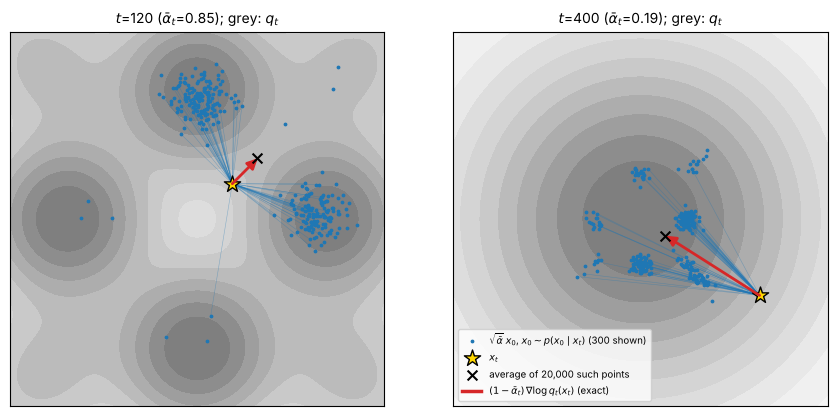

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
g = rng(7)
for ax, (x_t, t), lim in zip(axes, queries[:2], [1.6, 2.2]):
    x_t, a = x_t.double(), ABAR[t].item()
    show_density(ax, gmm.noised(a), lim=lim)
    targets = math.sqrt(a) * sample_posterior(gmm, x_t, a, 20_000, generator=g)      # x_t + (1-abar) * cond. score
    for p in targets[:60]:
        ax.plot([x_t[0], p[0]], [x_t[1], p[1]], color=C["learned"], lw=0.4, alpha=0.4)
    ax.scatter(targets[:300, 0], targets[:300, 1], s=3, color=C["learned"],
               label=r"$\sqrt{\bar\alpha}\,x_0$, $x_0\sim p(x_0\mid x_t)$ (300 shown)")
    mc_end = targets.mean(0)                    # average over all 20,000 posterior samples: small Monte Carlo error
    exact_end = x_t + (1 - a) * gmm_score(gmm.noised(a), x_t[None])[0]
    ax.scatter(*x_t.numpy(), marker="*", s=150, color="gold", edgecolor="k", zorder=5, label="$x_t$")
    # a FancyArrowPatch ends exactly at its end point (an empty-text ax.annotate arrow can stop short of it)
    ax.add_patch(FancyArrowPatch(tuple(x_t.tolist()), tuple(exact_end.tolist()), arrowstyle="-|>", color=C["exact"], lw=2,
                                 mutation_scale=15, shrinkA=0, shrinkB=0, zorder=8))
    ax.scatter(*mc_end.numpy(), marker="x", s=50, color="k", lw=1.5, zorder=9, label="average of 20,000 such points")
    ax.plot([], [], color=C["exact"], lw=2.5, label=r"$(1-\bar\alpha_t)\,\nabla\log q_t(x_t)$ (exact)")
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), title=rf"$t$={t} ($\bar\alpha_t$={a:.2f}); grey: $q_t$")
axes[1].legend(loc="lower left", fontsize=7)
plt.tight_layout()
plt.show()

Each thin line is one conditional score ("the noise pointed away from *this* $x_0$"). On the left, $x_t$ sits between two
components, so the posterior over $x_0$ is split between them. The individual conditional scores disagree wildly. Their average
(black cross) sits at the tip of the exact marginal score (red arrow), up to a small Monte Carlo error, *between* the two clusters. On the right the noise
is large: the posterior spreads over most components, and the score points towards the centre of the (shrunken) data. The network in
DDPM is trained on the noisy thin lines and learns their average.

Second check: $J_\text{DSM}(s) - J_\text{ESM}(s)$ should be the same constant for *every* candidate score function $s$.
We evaluate four quite different candidates on the same Monte Carlo samples, in $\epsilon$-units (multiplied by
$1-\bar\alpha_t$ and averaged over coordinates, like the DDPM loss): the exact score, the score of the best single Gaussian
(moment-matched to $q_t$, a linear score field), the exact score of the *wrong* noise level, and the zero function.

exact score                              DSM 0.4645 = ESM 0.0000 + gap 0.4645   (gap - exact gap: +0.0e+00, +0.0 SE)
best single Gaussian                     DSM 0.9010 = ESM 0.4365 + gap 0.4645   (gap - exact gap: +6.7e-05, +0.1 SE)
exact score at t=300 (wrong noise level) DSM 0.8857 = ESM 0.4212 + gap 0.4645   (gap - exact gap: +7.5e-05, +0.1 SE)
zero                                     DSM 1.0001 = ESM 0.5356 + gap 0.4645   (gap - exact gap: +4.1e-05, +0.0 SE)
the gap is the same for every candidate (to Monte Carlo error): it is the Bayes-optimal loss of notebook 02


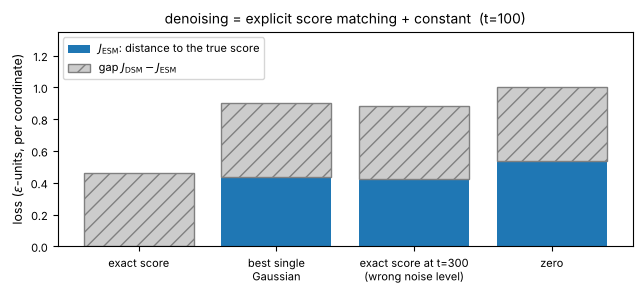

In [18]:
def gaussian_fit_score(dist, x):
    """Score of the single Gaussian with the same mean and covariance as the mixture `dist` (a linear vector field)."""
    mean = (dist.weights[:, None] * dist.means).sum(0)
    second = (dist.weights[:, None, None] * (dist.covs + dist.means[:, :, None] * dist.means[:, None, :])).sum(0)
    cov = second - torch.outer(mean, mean)
    return -(x - mean) @ torch.linalg.inv(cov)                         # cov is symmetric, so no transpose needed


t_chk = 100
a = ABAR[t_chk].item()
g = rng(8)
x0 = gmm.sample(N_MC, generator=g).double()
eps = torch.randn(N_MC, 2, dtype=torch.float64, generator=g)
x_t = math.sqrt(a) * x0 + math.sqrt(1 - a) * eps
cond_score = -eps / math.sqrt(1 - a)                                   # the DSM regression target
s_star = gmm_score(gmm.noised(a), x_t)                                 # the true marginal score
candidates = {"exact score": s_star,
              "best single\nGaussian": gaussian_fit_score(gmm.noised(a), x_t),
              "exact score at t=300\n(wrong noise level)": gmm_score(gmm.noised(ABAR[300].item()), x_t),
              "zero": torch.zeros_like(s_star)}
rows = []
gap_exact = (1 - a) * ((s_star - cond_score) ** 2).mean(1)            # per-sample gap of the exact score
for name, s in candidates.items():
    dsm_i = (1 - a) * ((s - cond_score) ** 2).mean(1)                 # per-sample losses, averaged over coordinates
    esm_i = (1 - a) * ((s - s_star) ** 2).mean(1)
    dsm, esm = dsm_i.mean().item(), esm_i.mean().item()
    # (this candidate's gap - the exact score's gap), per sample. Algebra: it equals (1-abar) (s - s*).(s* - cond) for d=2,
    # i.e. exactly the cross term of the derivation, whose expectation is 0. We test it against its Monte Carlo standard error.
    diff = (dsm_i - esm_i) - gap_exact
    z = diff.mean().item() / (diff.std().item() / math.sqrt(N_MC) + 1e-300)
    rows.append((name, dsm, esm))
    print(f"{name.replace(chr(10), ' '):40s} DSM {dsm:.4f} = ESM {esm:.4f} + gap {dsm - esm:.4f}   "
          f"(gap - exact gap: {diff.mean().item():+.1e}, {z:+.1f} SE)")
    assert abs(z) < 5, "the DSM - ESM gap should not depend on the candidate"
gaps = np.array([r[1] - r[2] for r in rows])
print(f"the gap is the same for every candidate (to Monte Carlo error): it is the Bayes-optimal loss of notebook 02")

fig, ax = plt.subplots(figsize=(6.5, 3.0))
names = [r[0] for r in rows]
ax.bar(names, [r[2] for r in rows], color=C["learned"], label=r"$J_\mathrm{ESM}$: distance to the true score")
ax.bar(names, gaps, bottom=[r[2] for r in rows], color="0.8", hatch="//", edgecolor="0.5",
       label=r"gap $J_\mathrm{DSM}-J_\mathrm{ESM}$")
ax.set(ylabel=r"loss ($\epsilon$-units, per coordinate)", title=f"denoising = explicit score matching + constant  (t={t_chk})")
ax.set_ylim(0, 1.35 * max(r[1] for r in rows))   # head-room for the legend
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

The hatched part, the irreducible noise in the regression target, is the same for every candidate. The printed deviation of a
candidate's gap from the exact score's gap is, sample by sample, exactly the cross term of the derivation,
$(1-\bar\alpha)\,(s-s^*)\cdot(s^*-\nabla\log q(x_t\mid x_0))$ in these units. So each candidate tests the identity
$\mathbb E[s^*-\nabla\log q(x_t\mid x_0)\mid x_t]=0$ along a different direction $s-s^*$, and every deviation is within Monte Carlo
error. (Avoid candidates of the form $\lambda s^*$: they all test the same direction, so their deviations are identical up to a
factor and carry no extra information.) So ranking score
functions by the denoising loss (which we *can* compute from data) ranks them exactly as the explicit loss (which needs the unknown
true score) would. The total for the exact score is the Bayes-optimal loss at this $t$. Averaged over $t$, that is the floor
notebook 02's training loss plateaued at.

## 6 · Tweedie's formula: the score is a denoiser

Take the identity of §5 and substitute the Gaussian conditional score:
$$\nabla\log q_t(x_t) = \mathbb E\Big[-\frac{x_t-\sqrt{\bar\alpha_t}\,x_0}{1-\bar\alpha_t}\,\Big|\,x_t\Big]
= -\frac{x_t-\sqrt{\bar\alpha_t}\,\mathbb E[x_0\mid x_t]}{1-\bar\alpha_t}.$$
Solving for the posterior mean gives **Tweedie's formula**:
$$\boxed{\ \mathbb E[x_0\mid x_t] = \frac{x_t + (1-\bar\alpha_t)\,\nabla\log q_t(x_t)}{\sqrt{\bar\alpha_t}}\ }
\qquad\text{equivalently}\qquad \mathbb E[\epsilon\mid x_t] = -\sqrt{1-\bar\alpha_t}\;\nabla\log q_t(x_t).$$
In the plain "observation = signal + Gaussian noise" form $y=x+\sigma n$, it reads $\mathbb E[x\mid y]=y+\sigma^2\nabla\log p_Y(y)$.

**The Bayesian reading.** Think of $x_t$ as a noisy measurement of a latent $x_0$, with the data distribution as the prior. Then
$\mathbb E[x_0\mid x_t]$ is the posterior mean, the **minimum-mean-squared-error (MMSE) estimate** of an ideal Bayesian observer.
Tweedie says the observer does not need the prior explicitly: the score of the *marginal distribution of the
measurements* is enough. This is Robbins/Efron's *empirical Bayes*, where the marginal is learnable from noisy data alone. For diffusion models
it means that
- the three outputs a network can be trained to produce ($\epsilon$, $x_0$, or the score) are **affine reparameterisations of the same function**;
- a model's $x_0$-prediction $\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta)/\sqrt{\bar\alpha_t}$ (what `dm.model_predictions` returns) *is*
  Tweedie's formula with the learned score. It estimates the posterior mean, not a sample.

*Side note — safe to skim: confirms that Tweedie's formula equals the exact posterior mean to float64 precision; the one thing to keep is `tweedie_x0`, the boxed formula as code, which the next cells use.*

**Check.** For our mixture we can compute $\mathbb E[x_0\mid x_t]=\sum_k r_k(x_t)\,m_k(x_t)$ by Gaussian conditioning (§5) and compare it with
Tweedie's formula applied to the exact score. One route conditions each Gaussian component on $x_t$; the other differentiates the
noised density. They share only the component responsibilities $r_k(x_t)$.

In [19]:
def tweedie_x0(score, x_t, abar):
    """Tweedie's formula: posterior mean E[x0 | x_t] from the score of the noised marginal q_t."""
    return (x_t + (1 - abar) * score) / math.sqrt(abar)


worst = 0.0
g = rng(9)
for t in [0, 10, 100, 300, 600, 999]:
    a = ABAR[t].item()
    x_t = gmm.noised(a).sample(2000, generator=g).double()
    r, m, _ = gmm_posterior(gmm, x_t, a)
    by_conditioning = (r[..., None] * m).sum(1)
    by_tweedie = tweedie_x0(gmm_score(gmm.noised(a), x_t), x_t, a)
    err = (by_conditioning - by_tweedie).abs().max().item()
    worst = max(worst, err)
    print(f"t={t:4d}  abar={a:.5f}   max |E[x0|x_t] (conditioning) - Tweedie(exact score)| = {err:.1e}")
assert worst < 1e-8
print("Tweedie's formula == exact posterior mean (float64 precision)  ✓")

t=   0  abar=0.99990   max |E[x0|x_t] (conditioning) - Tweedie(exact score)| = 8.9e-16
t=  10  abar=0.99781   max |E[x0|x_t] (conditioning) - Tweedie(exact score)| = 8.9e-16
t= 100  abar=0.89514   max |E[x0|x_t] (conditioning) - Tweedie(exact score)| = 8.9e-16
t= 300  abar=0.39401   max |E[x0|x_t] (conditioning) - Tweedie(exact score)| = 2.0e-15
t= 600  abar=0.02557   max |E[x0|x_t] (conditioning) - Tweedie(exact score)| = 7.1e-15
t= 999  abar=0.00004   max |E[x0|x_t] (conditioning) - Tweedie(exact score)| = 1.9e-13
Tweedie's formula == exact posterior mean (float64 precision)  ✓


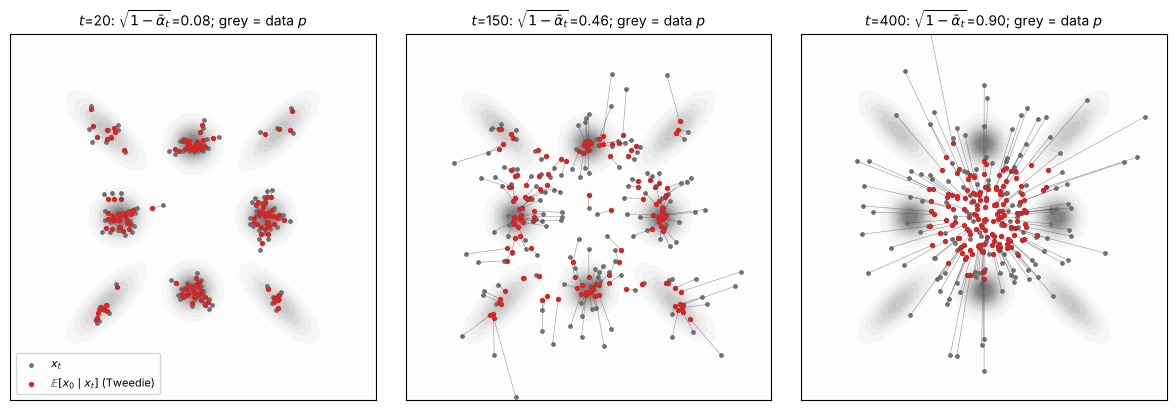

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.0))
g = rng(10)
for ax, t in zip(axes, [20, 150, 400]):
    a = ABAR[t].item()
    x_t = gmm.noised(a).sample(150, generator=g).double()
    x0_hat = tweedie_x0(gmm_score(gmm.noised(a), x_t), x_t, a)
    show_density(ax, gmm)
    for p, q in zip(x_t, x0_hat):
        ax.plot([p[0], q[0]], [p[1], q[1]], color="0.3", lw=0.4, alpha=0.6)
    ax.scatter(x_t[:, 0], x_t[:, 1], s=6, color=C["data"], label="$x_t$")
    ax.scatter(x0_hat[:, 0], x0_hat[:, 1], s=8, color=C["exact"], label=r"$\mathbb{E}[x_0\mid x_t]$ (Tweedie)")
    ax.set(title=rf"$t$={t}: $\sqrt{{1-\bar\alpha_t}}$={math.sqrt(1 - a):.2f}; grey = data $p$")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

At small $t$ (left) the posterior mean is essentially $x_t$ pulled onto the nearest component. At intermediate $t$ (middle)
many denoised points land *between* components, in regions where the data have almost no mass: the posterior is split
between several components and its mean is their weighted average. At large $t$ (right) everything collapses
towards the global mean of the data. This is why a one-shot denoiser produces blurry averages, and why diffusion models
denoise in many small steps. Each step only asks for the posterior mean over a *small* noise increment, where the posterior is
nearly Gaussian (notebook 02, §1), and fresh noise is injected between steps so the chain commits to one component
instead of averaging over them.

## 7 · A learned score vs the exact score

Now train an $\epsilon$-model as in notebook 02, with the library versions of its parts (`dm.MLPDenoiser`, and `dm.train_diffusion`,
which is notebook 02's loop with Adam, gradient clipping and EMA plus a short learning-rate warm-up; linear schedule, $T=1000$) on the
training set of §3b, convert it into a score with $s_\theta(x,t)=-\epsilon_\theta(x,t)/\sqrt{1-\bar\alpha_t}$, and compare it with
the exact score of $q_t$. We use 128 hidden units instead of the default 256: in 2-D that is plenty, and it trains twice as fast.

In [21]:
dm.seed_everything(0)
net = dm.MLPDenoiser(data_dim=2, hidden=128)
out = dm.train_diffusion(net, train_data, sched, steps=STEPS, batch_size=256, lr=1e-3, device=device,
                         progress=False, log_every=max(STEPS // 4, 1))
score_net = out["ema"].model                       # sample / evaluate with the EMA weights (notebook 02, §8)
print(f"{dm.count_params(net) / 1e3:.0f}k parameters, trained in {out['seconds']:.0f} s")


@torch.no_grad()
def learned_score(model, x, t):
    """s_theta(x, t) = -eps_theta(x, t) / sqrt(1 - abar_t), for a batch x and an integer timestep t. float64 on the CPU."""
    tt = torch.full((x.shape[0],), int(t), device=device, dtype=torch.long)
    eps_hat = model(x.float().to(device), tt).cpu().double()        # .cpu() first: MPS has no float64
    return -eps_hat / math.sqrt(1 - ABAR[t].item())


# CHECK: dm.model_predictions' x0-prediction is Tweedie's formula applied to the learned score.
x_chk = gmm.noised(ABAR[200].item()).sample(500, generator=rng(11))
_, x0_dm = dm.model_predictions(score_net, x_chk.to(device), 200, sched)
x0_tw = tweedie_x0(learned_score(score_net, x_chk, 200), x_chk.double(), ABAR[200].item())
assert torch.allclose(x0_dm.cpu().double(), x0_tw, atol=1e-4)
print("dm.model_predictions(...)[1] == Tweedie(learned score)  ✓")

step   1000 | loss 0.2760


step   2000 | loss 0.2327


step   3000 | loss 0.2299


step   4000 | loss 0.2291
126k parameters, trained in 26 s
dm.model_predictions(...)[1] == Tweedie(learned score)  ✓


**Where is the learned score accurate?** Top two rows: score directions at four noise levels (exact, then learned), with
grey contours enclosing 50%, 90% and 99% of the mass of $q_t$.
Bottom row: the pointwise error $\|s_\theta-s^*\|$ in units of the *typical* score size at that noise level,
$\sqrt{\mathbb E_{q_t}\|s^*\|^2}$, on a log colour scale, with the same contours in white. (Dividing by the local $\|s^*\|$ instead
would blow up wherever the true score happens to be near zero: at modes, saddles and on flat plateaus.)

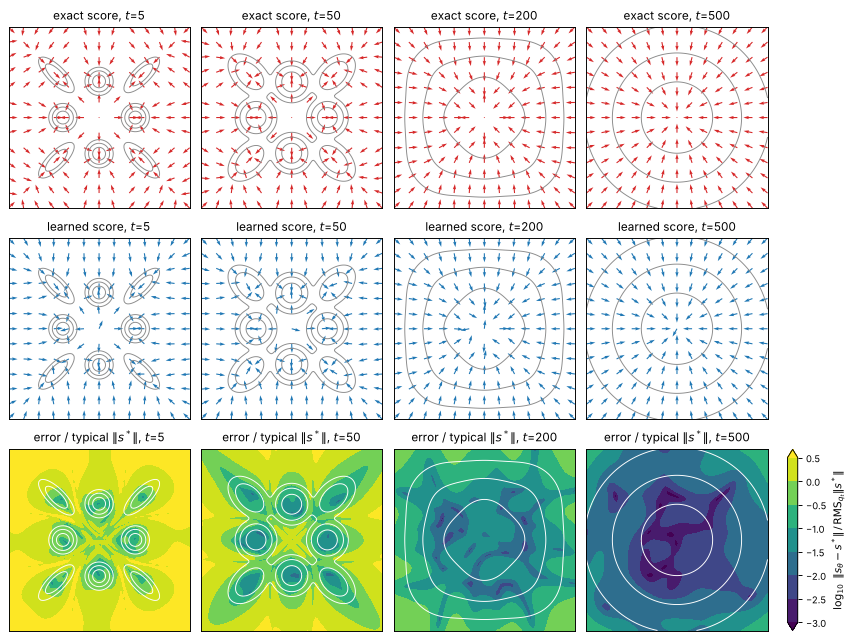

In [22]:
def hdr_levels(dist, masses=(0.99, 0.9, 0.5), n=20_000):
    """Log-density thresholds whose super-level sets contain the given probability masses (increasing order)."""
    lp = dist.log_prob(dist.sample(n, generator=torch.Generator().manual_seed(0)))
    return [torch.quantile(lp, 1 - m).item() for m in masses]


T_SHOW = [5, 50, 200, 500]
fig, axes = plt.subplots(3, len(T_SHOW), figsize=(10, 7.6), dpi=85)   # slightly lower dpi: 8 quiver panels make a big PNG
err_levels = np.linspace(-3, 0.5, 8)           # log10 error bands, half a decade each
n_grid = 120
gx = torch.linspace(-LIM, LIM, n_grid, dtype=torch.float64)
GX, GY = torch.meshgrid(gx, gx, indexing="xy")
grid_pts = torch.stack([GX.flatten(), GY.flatten()], 1)
for j, t in enumerate(T_SHOW):
    q_t = gmm.noised(ABAR[t].item())
    log_q = q_t.log_prob(grid_pts).reshape(n_grid, n_grid).numpy()
    levels = hdr_levels(q_t)                       # contours enclosing 99%, 90% and 50% of the mass of q_t
    for i, (fn, col, lab) in enumerate([(lambda p: gmm_score(q_t, p), C["exact"], "exact"),
                                        (lambda p: learned_score(score_net, p, t), C["learned"], "learned")]):
        axes[i, j].contour(gx, gx, log_q, levels=levels, colors="0.55", linewidths=0.8, linestyles="solid")
        dm.plot_vector_field(lambda p: fn(p).float(), ax=axes[i, j], lim=LIM, n=13, normalize=True, color=col,
                             angles="xy", scale_units="xy", scale=1 / 0.3, width=0.006)
        axes[i, j].set(xticks=[], yticks=[], title=rf"{lab} score, $t$={t}")
    typical = gmm_score(q_t, q_t.sample(5000, generator=rng(12))).pow(2).sum(1).mean().sqrt()   # RMS score under q_t
    err = (learned_score(score_net, grid_pts, t) - gmm_score(q_t, grid_pts)).norm(dim=1) / typical
    im = axes[2, j].contourf(gx, gx, err.log10().reshape(n_grid, n_grid).numpy(), levels=err_levels, cmap="viridis",
                             extend="both")
    axes[2, j].contour(gx, gx, log_q, levels=levels, colors="w", linewidths=0.8, linestyles="solid")
    axes[2, j].set(xticks=[], yticks=[], aspect="equal", title=rf"error / typical $\|s^*\|$, $t$={t}")
plt.tight_layout(rect=[0, 0, 0.92, 1])
pos = axes[2, -1].get_position()
fig.colorbar(im, cax=fig.add_axes([0.93, pos.y0, 0.012, pos.height]),
             label=r"$\log_{10}\ \|s_\theta-s^*\| \,/\, \mathrm{RMS}_{q_t}\|s^*\|$")
plt.show()

The arrow fields look alike almost everywhere: the network has learned the right *directions*. The error maps show where the
*magnitudes* go wrong. Inside the contours, where the noised training data actually live, the error is a small fraction of the
typical score, at least in the cores of the components (at $t=5$ it already reaches a few tens of per cent near the outer
contour). Outside them it grows, most of all at small $t$ and far from the data, where the network has to extrapolate into
the empty space of §3b. As $t$ grows, $q_t$ spreads out, the contours widen and the well-learned region grows with them. This is
failure mode 3b made visible, and the reason sampling starts at high noise: there, the score is accurate everywhere the sampler can be.

Now the same comparison as a function of $t$, averaged over two kinds of points: **typical** points $x\sim q_t$ (this is what
the training loss weights), and **atypical** points of the square $[-4,4]^2$ that lie *outside* the 99% contour of $q_t$.

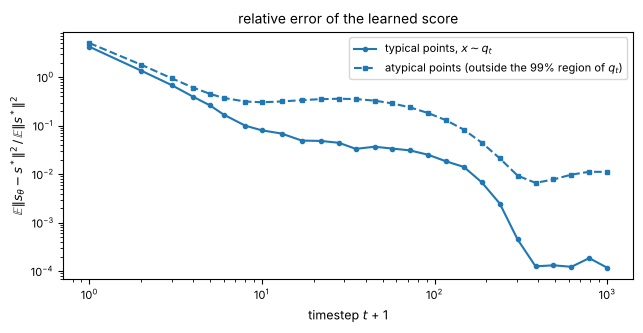

t=   0: relative error typical 4.3e+00 | atypical 5.1e+00 (ratio   1.2) | atypical share of the box 92%
t=   4: relative error typical 2.6e-01 | atypical 4.5e-01 (ratio   1.7) | atypical share of the box 92%
t=  12: relative error typical 6.9e-02 | atypical 3.2e-01 (ratio   4.6) | atypical share of the box 90%
t=  34: relative error typical 3.3e-02 | atypical 3.5e-01 (ratio  10.6) | atypical share of the box 86%
t=  91: relative error typical 2.5e-02 | atypical 1.8e-01 (ratio   7.2) | atypical share of the box 74%
t= 238: relative error typical 2.5e-03 | atypical 2.1e-02 (ratio   8.6) | atypical share of the box 60%
t= 620: relative error typical 1.2e-04 | atypical 9.8e-03 (ratio  79.6) | atypical share of the box 55%
atypical / typical error: 1.2x to 10.6x for t <= 250, 21x to 94x for t > 250
relative error at the smallest t, typical points: 4.3  (> 1 means worse than predicting a zero score)


In [23]:
t_eval = np.unique(np.geomspace(1, 1000, 30 if not FAST else 8).astype(int) - 1)
g4 = torch.linspace(-4, 4, 80, dtype=torch.float64)
G4X, G4Y = torch.meshgrid(g4, g4, indexing="xy")
box_pts = torch.stack([G4X.flatten(), G4Y.flatten()], 1)
err_typ, err_atyp, frac_atyp = [], [], []
g = rng(13)
for t in t_eval:
    q_t = gmm.noised(ABAR[t].item())
    x_typ = q_t.sample(2000, generator=g).double()
    s_true = gmm_score(q_t, x_typ)
    err_typ.append(((learned_score(score_net, x_typ, t) - s_true) ** 2).sum(1).mean().item()
                   / (s_true ** 2).sum(1).mean().item())
    x_atyp = box_pts[q_t.log_prob(box_pts) < hdr_levels(q_t, masses=(0.99,))[0]]
    s_true = gmm_score(q_t, x_atyp)
    err_atyp.append(((learned_score(score_net, x_atyp, t) - s_true) ** 2).sum(1).mean().item()
                    / (s_true ** 2).sum(1).mean().item())
    frac_atyp.append(len(x_atyp) / len(box_pts))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(t_eval + 1, err_typ, color=C["learned"], marker="o", ms=3, label=r"typical points, $x\sim q_t$")
ax.plot(t_eval + 1, err_atyp, color=C["learned"], ls="--", marker="s", ms=3,
        label="atypical points (outside the 99% region of $q_t$)")
ax.set(xscale="log", yscale="log", xlabel="timestep $t$ + 1", ylabel=r"$\mathbb{E}\|s_\theta-s^*\|^2\,/\,\mathbb{E}\|s^*\|^2$",
       title="relative error of the learned score")
ax.legend()
plt.tight_layout()
plt.show()
for t, e1, e2, f in list(zip(t_eval, err_typ, err_atyp, frac_atyp))[:: max(len(t_eval) // 6, 1)]:
    print(f"t={t:4d}: relative error typical {e1:.1e} | atypical {e2:.1e} (ratio {e2 / e1:5.1f}) | "
          f"atypical share of the box {f:.0%}")
ratio = np.array(err_atyp) / np.array(err_typ)
mid = t_eval <= 250
print(f"atypical / typical error: {ratio[mid].min():.1f}x to {ratio[mid].max():.1f}x for t <= 250, "
      f"{ratio[~mid].min():.0f}x to {ratio[~mid].max():.0f}x for t > 250")
print(f"relative error at the smallest t, typical points: {err_typ[0]:.1f}  (> 1 means worse than predicting a zero score)")

Two regularities, both worth remembering:
- **Atypical points are worse** than typical ones at every $t$ (see the printed ratios): only slightly at the very smallest
  $t$, where both are bad; several-fold, up to about tenfold, at small and intermediate $t$; and by far more at large $t$,
  where the typical-point error becomes tiny. The training loss is an expectation under $q_t$ and simply does not see
  atypical points.
- **Small $t$ is hard even at typical points.** The relative error is largest at the lowest noise levels. At the very smallest
  $t$ it even exceeds 1: there the learned score is *worse than the zero function*. The regression target $\epsilon$ there
  is almost pure noise: the predictable part $\mathbb E[\epsilon\mid x_t]=-\sqrt{1-\bar\alpha_t}\,s^*$ is tiny compared with the
  target's unit variance, so many samples are needed to pin it down (the denoising-score-matching variance problem). In absolute
  score units the error is further amplified by $1/\sqrt{1-\bar\alpha_t}$.

> **Gotcha: the score at tiny noise.** For ancestral sampling these small-$t$ errors hardly matter, because the sampler only uses the
> score through $\hat x_0 = (x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta)/\sqrt{\bar\alpha_t}$, where an $\epsilon$-error is multiplied by the tiny
> $\sqrt{1-\bar\alpha_t}$. They do matter for anything that uses the score *itself* at low noise: exact likelihoods via the
> probability-flow ODE (notebook 04), which integrate the divergence of the score down to the smallest noise level, or using
> $s_\theta$ as the gradient of a log-prior inside MCMC or optimisation (e.g. for inverse problems), where the step size is set
> by something other than the noise level.
> That is why practical systems stop at a minimum noise level $\sigma_\text{min}>0$ and parameterise the network as a noise or data predictor rather than as a raw score.

## 8 · Plugging the exact score into the DDPM sampler

If a perfect score gives perfect samples, then whatever is left in a learned model's samples is *model* error, not
*sampler* error. We can test this directly: wrap the exact score as a model with the `dmtools` signature
`model(x, t, y=None)` returning $\epsilon^*=-\sqrt{1-\bar\alpha_t}\,\nabla\log q_t(x)$, and hand it to the unchanged `dm.ddpm_sample`.

In [24]:
class ExactScoreModel:
    """A drop-in 'network' whose eps-prediction is exact: eps*(x, t) = -sqrt(1-abar_t) * grad log q_t(x).

    q_t is the VP-noised version of a dm.GaussianMixture; one mixture per timestep is precomputed.
    """

    def __init__(self, gmm, schedule):
        abar = schedule.alpha_bars.cpu().double()       # .cpu() first: MPS has no float64
        self.s1a = (1 - abar).sqrt()
        self.q_t = [gmm.noised(a) for a in abar.tolist()]

    def __call__(self, x, t, y=None):
        out = torch.empty_like(x)
        for tv in t.unique().tolist():                   # samplers pass one t per batch, but be general
            m = t == tv
            score = gmm_score(self.q_t[tv], x[m].cpu())  # float64 on the CPU
            out[m] = (-self.s1a[tv] * score).to(x.device, x.dtype)
        return out


exact_model = ExactScoreModel(gmm, sched)
x_true = gmm.sample(N_SAMPLE, generator=torch.Generator().manual_seed(11))     # the reference set for every metric
g_ref = torch.Generator().manual_seed(12)
floor_sets = [gmm.sample(N_SAMPLE, generator=g_ref) for _ in range(5)]         # fresh exact samples: the metrics' floor
t0 = time.time()
x_exact = dm.ddpm_sample(exact_model, sched, (N_SAMPLE, 2), generator=torch.Generator(device=device).manual_seed(1))
t_exact = time.time() - t0
t0 = time.time()
x_learned = dm.ddpm_sample(score_net, sched, (N_SAMPLE, 2), generator=torch.Generator(device=device).manual_seed(1))
t_learned = time.time() - t0
print(f"sampling time ({N_SAMPLE} points, 1000 steps): exact {t_exact:.1f} s, learned {t_learned:.1f} s")
fl_mmd = np.array([dm.mmd_rbf(x, x_true) for x in floor_sets])
fl_sw = np.array([dm.sliced_wasserstein(x, x_true) for x in floor_sets])
print(f"{'floor (5 fresh sets)':22s}  MMD^2 {fl_mmd.mean():.4f} ± {fl_mmd.std():.4f}   sliced W1 {fl_sw.mean():.4f} ± {fl_sw.std():.4f}")
metrics = {}
for name, x in [("DDPM + exact score", x_exact), ("DDPM + learned score", x_learned)]:
    metrics[name] = (dm.mmd_rbf(x.cpu(), x_true), dm.sliced_wasserstein(x.cpu(), x_true))
    print(f"{name:22s}  MMD^2 {metrics[name][0]:.4f}            sliced W1 {metrics[name][1]:.4f}")

# Mode weights: the failure of plain Langevin (§3a). Which component does each sample belong to?
w = gmm.weights.numpy()
se_w = np.sqrt(w * (1 - w) / N_SAMPLE)                    # binomial standard error of each fraction
print(f"\n{'true weights':22s}  {w.round(3)}")
for name, x in [("DDPM + exact score", x_exact), ("DDPM + learned score", x_learned)]:
    frac = np.bincount(gmm.responsibilities(x.cpu()).argmax(1).numpy(), minlength=gmm.K) / N_SAMPLE
    print(f"{name:22s}  {frac.round(3)}   largest deviation {np.abs((frac - w) / se_w).max():.1f} SE")

# Tails: MMD with these bandwidths barely registers a few per cent of misplaced samples. A tail-sensitive metric:
# the fraction of samples outside the region that holds 99% of the mass of p (by definition 1% for exact samples).
thr99 = hdr_levels(gmm, masses=(0.99,))[0]


def frac_outside(x):
    """Fraction of samples in the low-density region log p(x) < thr99 (expected: 0.01 for samples of p)."""
    return (gmm.log_prob(x.cpu()) < thr99).double().mean().item()


se_tail = math.sqrt(0.01 * 0.99 / N_SAMPLE)
out_floor = np.array([frac_outside(x) for x in floor_sets])
tails = {"fresh true samples": out_floor.mean()}
print(f"\nfraction of samples outside the 99% region of p (expected 0.010, binomial SE {se_tail:.3f}):")
print(f"{'fresh true samples':22s}  {out_floor.mean():.3f} ± {out_floor.std():.3f} (5 sets)")
for name, x in [("DDPM + exact score", x_exact), ("DDPM + learned score", x_learned)]:
    tails[name] = frac_outside(x)
    print(f"{name:22s}  {tails[name]:.3f}   = {tails[name] / 0.01:.1f}x the expected 1%, {(tails[name] - 0.01) / se_tail:+.1f} SE")

sampling time (2000 points, 1000 steps): exact 1.8 s, learned 9.6 s


floor (5 fresh sets)    MMD^2 0.0046 ± 0.0015   sliced W1 0.0353 ± 0.0096


DDPM + exact score      MMD^2 0.0030            sliced W1 0.0218


DDPM + learned score    MMD^2 0.0036            sliced W1 0.0243

true weights            [0.188 0.062 0.188 0.062 0.188 0.062 0.188 0.062]
DDPM + exact score      [0.184 0.064 0.192 0.058 0.186 0.064 0.191 0.06 ]   largest deviation 0.7 SE
DDPM + learned score    [0.177 0.068 0.194 0.055 0.184 0.064 0.197 0.06 ]   largest deviation 1.4 SE

fraction of samples outside the 99% region of p (expected 0.010, binomial SE 0.002):
fresh true samples      0.009 ± 0.002 (5 sets)
DDPM + exact score      0.006   = 0.6x the expected 1%, -1.8 SE
DDPM + learned score    0.042   = 4.2x the expected 1%, +14.4 SE


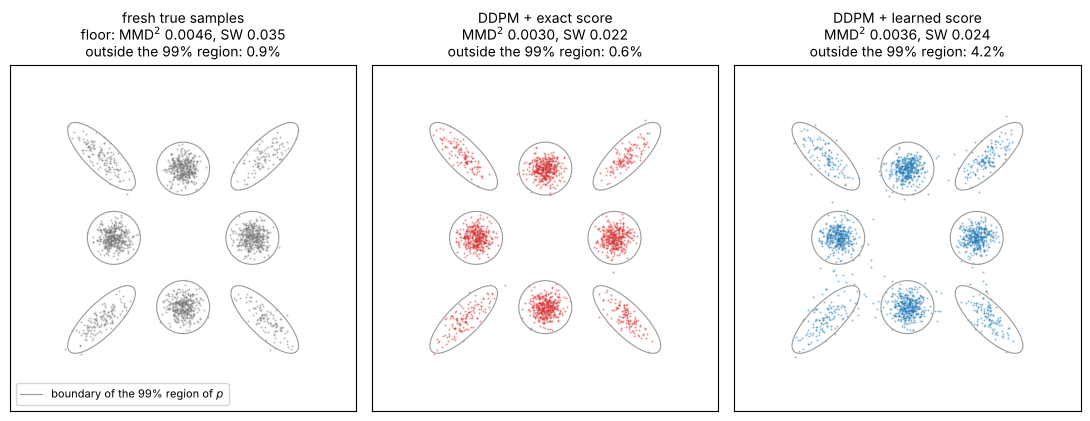

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4.0))
gq = torch.linspace(-LIM, LIM, 200, dtype=torch.float64)
GQX, GQY = torch.meshgrid(gq, gq, indexing="xy")
log_p_grid = gmm.log_prob(torch.stack([GQX.flatten(), GQY.flatten()], 1)).reshape(200, 200).numpy()
panels = [("fresh true samples", floor_sets[0], C["data"],
           f"floor: MMD$^2$ {fl_mmd.mean():.4f}, SW {fl_sw.mean():.3f}"),
          ("DDPM + exact score", x_exact, C["exact"], f"MMD$^2$ {metrics['DDPM + exact score'][0]:.4f}, "
                                                        f"SW {metrics['DDPM + exact score'][1]:.3f}"),
          ("DDPM + learned score", x_learned, C["learned"], f"MMD$^2$ {metrics['DDPM + learned score'][0]:.4f}, "
                                                            f"SW {metrics['DDPM + learned score'][1]:.3f}")]
for ax, (name, x, col, line2) in zip(axes, panels):
    ax.contour(gq, gq, log_p_grid, levels=[thr99], colors="0.6", linewidths=0.8, linestyles="solid")
    dm.scatter2d(x.cpu(), ax=ax, s=2, alpha=0.5, c=col, lim=LIM,
                 title=f"{name}\n{line2}\noutside the 99% region: {tails[name]:.1%}")
axes[0].plot([], [], color="0.6", lw=0.8, label="boundary of the 99% region of $p$")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

With the exact score, DDPM's 1000 small steps reproduce the data distribution to within the sampling noise of the metrics
(compare with the floor of fresh true samples), so the sampler's own discretisation error is negligible here. Unlike plain
Langevin in §2, DDPM also gets the **mode weights** right (see the printed fractions and the bar chart below): it too
travels from high noise to low noise, and at high noise the modes are connected (§4).

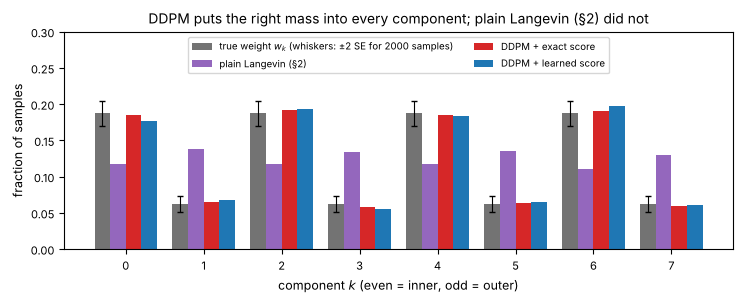

In [26]:
viz_k = np.arange(gmm.K)
viz_bars = [(f"true weight $w_k$ (whiskers: ±2 SE for {N_SAMPLE} samples)", gmm.weights.numpy(), C["data"]),
            ("plain Langevin (§2)", frac_lan.numpy(), C["plain"])]
for viz_name, viz_xs, viz_col in [("DDPM + exact score", x_exact, C["exact"]),
                                  ("DDPM + learned score", x_learned, C["learned"])]:
    viz_comp = gmm.responsibilities(viz_xs.cpu()).argmax(1).numpy()             # most likely component of each sample
    viz_bars.append((viz_name, np.bincount(viz_comp, minlength=gmm.K) / len(viz_xs), viz_col))
viz_fig, viz_ax = plt.subplots(figsize=(7.5, 3.1))
for viz_i, (viz_lab, viz_v, viz_col) in enumerate(viz_bars):
    viz_ax.bar(viz_k + (viz_i - 1.5) * 0.2, viz_v, 0.2, color=viz_col, label=viz_lab,
               yerr=2 * np.sqrt(viz_v * (1 - viz_v) / N_SAMPLE) if viz_i == 0 else None,
               error_kw=dict(lw=0.8, capsize=2))
viz_ax.set(xlabel="component $k$ (even = inner, odd = outer)", ylabel="fraction of samples", xticks=viz_k,
           ylim=(0, 0.3), title="DDPM puts the right mass into every component; plain Langevin (§2) did not")
viz_ax.legend(loc="upper center", ncol=2, fontsize=7)
plt.tight_layout()
plt.show()

Grey bars are the true weights, and the purple bars repeat plain Langevin's occupation (§3a, left panel): wrong in every
component. Both DDPM runs (red: exact score, blue: learned score) match the true weights to within sampling noise: their
largest deviations (printed above) are here below two standard errors.

On this easy 2-D problem the learned model lands close to the MMD floor as well, so by MMD alone the score error of §7 seems to
have vanished. It has not. The tail metric shows that the learned model puts several times too many samples *between* the
components (the stray blue points outside the grey boundary), while the exact-score sampler does not. Those are the
low-density errors of §7 made visible in the samples. MMD hardly sees them: if a fraction $f$ of the mass is misplaced,
MMD$^2$ grows only like $f^2$, which for a few per cent is below the metric's own sampling noise. This is the decomposition at work: the same sampler with
the exact score shows no excess, so the excess is *model* error, not sampler error. (Two lessons for practice: look at more
than one metric, and include one that is sensitive to the tails.) With few steps the picture changes, because a perfect score
with a coarse sampler is no longer perfect (notebook 04). Keeping an exact-score oracle around lets you attribute every bit of
error to the right culprit.

## 9 · Memorisation vs generalisation: the exact score of a training set

Here is a puzzle. In practice we never have $p$, only $N$ training points. The distribution they define is the **empirical
distribution** $\hat p=\frac1N\sum_i\delta_{x^{(i)}}$, and what the DDPM loss is minimised by, *on the training set*, is the score of
$\hat p$ noised. That score is easy to write down. Treat $\hat p$ as a mixture of $N$ tiny Gaussians $\mathcal N(x^{(i)},\tau^2 I)$ with
$\tau\to0$; its noised version is again a mixture, with components $\mathcal N(\sqrt{\bar\alpha_t}x^{(i)},v_t I)$ and $v_t=\bar\alpha_t\tau^2+1-\bar\alpha_t$. By
Tweedie, the **ideal denoiser of a training set** is a softmax-weighted average of training points:
$$\mathbb E_{\hat p}[x_0\mid x_t] \approx \sum_i w_i(x_t)\,x^{(i)},\qquad w_i(x_t)=\operatorname{softmax}_i\Big(-\frac{\|x_t-\sqrt{\bar\alpha_t}\,x^{(i)}\|^2}{2v_t}\Big).$$
As the noise level goes to zero the softmax becomes a hard nearest-neighbour assignment, so a sampler driven by this score
**can only output training points**. A perfectly optimised diffusion model is a lookup table. (With a finite smallest noise
level, DDPM's $\sqrt{1-\bar\alpha_1}=0.01$ here (array index 0), "hard" needs the training points to be much further apart than that; otherwise the
last step returns local averages of very close neighbours. We will see both.) Yet trained networks produce new samples.
Let us compare the two on the same training sets.

In [27]:
class EmpiricalScoreModel:
    """eps*(x, t) for the empirical distribution of `train`: a mixture of N tiny isotropic Gaussians (width tau)."""

    def __init__(self, train, schedule, tau=1e-3):
        self.train = train.cpu().double()
        self.abar = schedule.alpha_bars.cpu().double()                  # .cpu() first: MPS has no float64
        self.tau2 = tau ** 2

    def x0_hat(self, x, t):
        """The ideal denoiser: a softmax-weighted average of training points (posterior mean under p_hat)."""
        a = self.abar[t].item()
        v = a * self.tau2 + 1 - a                                        # variance of each noised component
        centres = math.sqrt(a) * self.train
        d2 = (x ** 2).sum(1, keepdim=True) - 2 * x @ centres.T + (centres ** 2).sum(1)  # squared distances (n, N)
        w = torch.softmax(-d2 / (2 * v), dim=1)
        within = self.tau2 * math.sqrt(a) / (a * self.tau2 + 1 - a)     # Gaussian-conditioning shrinkage inside a component
        return (w @ self.train) * (1 - within * math.sqrt(a)) + within * x

    def score(self, x, t):
        a = self.abar[t].item()
        return -(x - math.sqrt(a) * self.x0_hat(x, t)) / (1 - a)       # Tweedie, solved for the score

    def __call__(self, x, t, y=None):
        tv = int(t[0])                                                   # samplers pass one t per batch
        eps = -math.sqrt(1 - self.abar[tv].item()) * self.score(x.cpu().double(), tv)
        return eps.to(x.device, x.dtype)


# CHECK: the fast formula agrees with dm.GaussianMixture built on the same tiny-variance components.
g = rng(14)
pts_train = gmm.sample(16, generator=g)
emp = EmpiricalScoreModel(pts_train, sched)
emp_gmm = dm.GaussianMixture(torch.ones(16), pts_train, torch.full((16,), 1e-3 ** 2))
for t in [0, 50, 500]:
    xq = 1.5 * torch.randn(300, 2, dtype=torch.float64, generator=g)
    assert torch.allclose(emp.score(xq, t), gmm_score(emp_gmm.noised(ABAR[t].item()), xq), rtol=1e-6, atol=1e-6)
print("EmpiricalScoreModel.score == score of the noised tiny-Gaussian mixture  ✓")

EmpiricalScoreModel.score == score of the noised tiny-Gaussian mixture  ✓


Two training-set sizes: $N=32$ (four points per component on average) and $N=1000$. For each we sample with the exact empirical
score and with a network trained on exactly those points (same recipe as §7). We measure how close every sample lies to its
**nearest training point**. As a yardstick, fresh samples from the true $p$ show what "new data" looks like on this measure.

In [28]:
def nn_dist(x, train):
    """Distance from every row of x to its nearest training point."""
    return torch.cdist(x.cpu().double(), train.cpu().double()).min(1).values


def train_spacing(train):
    """Median distance from each training point to its nearest *other* training point."""
    d = torch.cdist(train.double(), train.double())
    return (d + torch.diag(torch.full((len(train),), float("inf"), dtype=torch.float64))).min(1).values.median().item()


N_SIZES = [32, 1000]
N_GEN = 256 if FAST else 1000
mem = {}
for n_tr in N_SIZES:
    train_n = gmm.sample(n_tr, generator=torch.Generator().manual_seed(100 + n_tr))
    t0 = time.time()
    x_emp = dm.ddpm_sample(EmpiricalScoreModel(train_n, sched), sched, (N_GEN, 2),
                           generator=torch.Generator(device=device).manual_seed(2))
    dm.seed_everything(0)
    out_n = dm.train_diffusion(dm.MLPDenoiser(data_dim=2, hidden=128), train_n, sched, steps=STEPS, batch_size=256,
                               lr=1e-3, device=device, progress=False)
    x_net = dm.ddpm_sample(out_n["ema"].model, sched, (N_GEN, 2), generator=torch.Generator(device=device).manual_seed(2))
    fresh = gmm.sample(N_GEN, generator=torch.Generator().manual_seed(7))
    held_out = gmm.sample(2000, generator=torch.Generator().manual_seed(8))
    mem[n_tr] = dict(train=train_n, emp=x_emp.cpu(), net=x_net.cpu(), fresh=fresh)
    print(f"N={n_tr} ({time.time() - t0:.0f} s): typical spacing of the training points {train_spacing(train_n):.3f} "
          f"(smallest noise level of the sampler: {math.sqrt(1 - ABAR[0].item()):.3f})")
    print(f"   {'training set itself':22s} {'':56s} | MMD^2 to held-out data {dm.mmd_rbf(train_n, held_out):.4f}")
    for name, x in [("exact empirical score", x_emp), ("trained network", x_net), ("fresh samples of p", fresh)]:
        d_nn = nn_dist(x, train_n)
        # "copy" = within 1e-3 (the width tau of the tiny Gaussians) of a training point
        print(f"   {name:22s} NN distance to training set: median {d_nn.median():.1e}, copies {(d_nn < 1e-3).double().mean():4.0%} | "
              f"MMD^2 to held-out data {dm.mmd_rbf(x.cpu(), held_out):.4f}")

N=32 (31 s): typical spacing of the training points 0.107 (smallest noise level of the sampler: 0.010)


   training set itself                                                             | MMD^2 to held-out data 0.1541


   exact empirical score  NN distance to training set: median 1.2e-04, copies  99% | MMD^2 to held-out data 0.1634


   trained network        NN distance to training set: median 8.9e-02, copies   0% | MMD^2 to held-out data 0.1329


   fresh samples of p     NN distance to training set: median 1.3e-01, copies   0% | MMD^2 to held-out data 0.0055


N=1000 (38 s): typical spacing of the training points 0.021 (smallest noise level of the sampler: 0.010)


   training set itself                                                             | MMD^2 to held-out data 0.0160


   exact empirical score  NN distance to training set: median 2.7e-03, copies  34% | MMD^2 to held-out data 0.0203


   trained network        NN distance to training set: median 2.4e-02, copies   0% | MMD^2 to held-out data 0.0156


   fresh samples of p     NN distance to training set: median 2.3e-02, copies   0% | MMD^2 to held-out data 0.0055


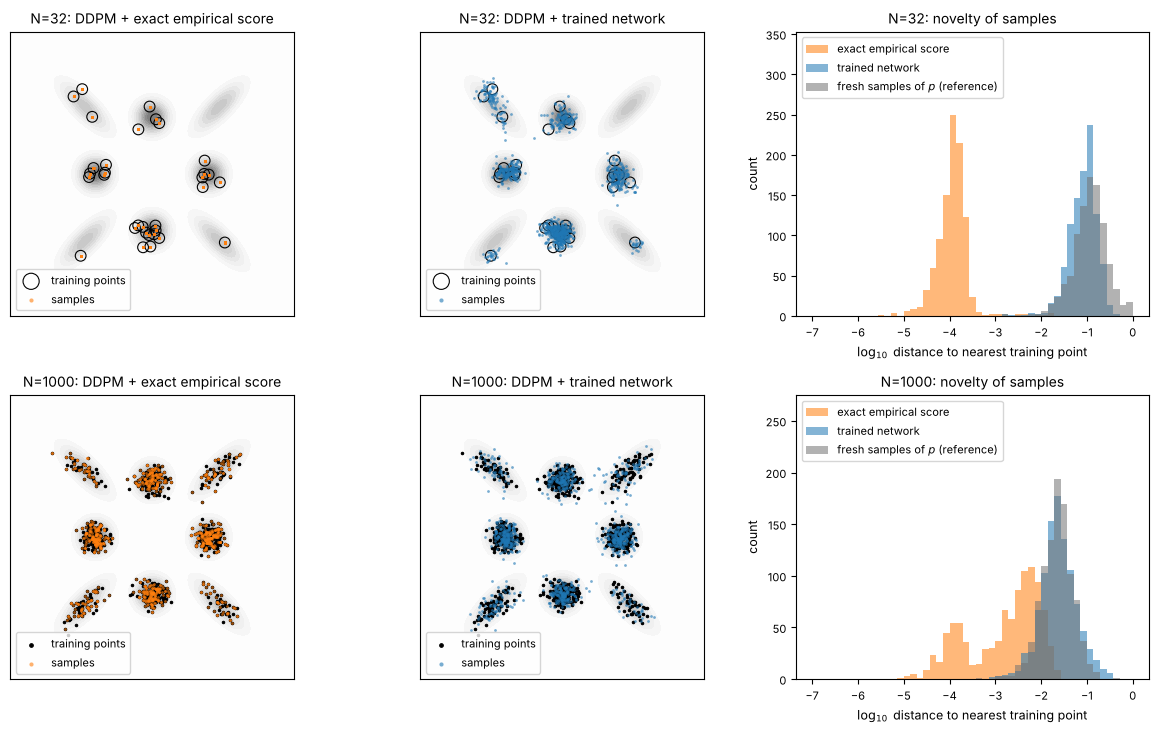

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.4))
bins = np.linspace(-7, 0, 50)
for row, n_tr in enumerate(N_SIZES):
    r = mem[n_tr]
    for col, (key, colr, lab) in enumerate([("emp", C["empirical"], "exact empirical score"),
                                            ("net", C["learned"], "trained network")]):
        ax = axes[row, col]
        show_density(ax, gmm)
        small = n_tr < 100   # few training points: hollow circles; many: small dots underneath the samples
        ax.scatter(r["train"][:, 0], r["train"][:, 1], s=60 if small else 3, facecolors="none" if small else C["train"],
                   edgecolors=C["train"], lw=0.8, zorder=2, label="training points")
        ax.scatter(r[key][:, 0], r[key][:, 1], s=4, alpha=0.6, color=colr, lw=0, zorder=3, label="samples")
        ax.set(xlim=(-LIM, LIM), ylim=(-LIM, LIM), aspect="equal", xticks=[], yticks=[])
        ax.set_title(f"N={n_tr}: DDPM + {lab}")
        ax.legend(loc="lower left", markerscale=1.5)
    ax = axes[row, 2]
    for key, colr, lab in [("emp", C["empirical"], "exact empirical score"), ("net", C["learned"], "trained network"),
                           ("fresh", C["data"], "fresh samples of $p$ (reference)")]:
        ax.hist(nn_dist(r[key], r["train"]).clamp(min=1e-7).log10().numpy(), bins=bins, color=colr, alpha=0.55,
                label=lab)
    ax.set(xlabel=r"$\log_{10}$ distance to nearest training point", ylabel="count", title=f"N={n_tr}: novelty of samples")
    ax.set_ylim(top=1.35 * ax.get_ylim()[1])   # head-room for the legend
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**The exact empirical score memorises at both sizes.** For $N=32$ essentially every sample is a copy of a training point: the
orange histogram sits far to the left, around $10^{-4}$, orders of magnitude closer than fresh data and even closer than the
width $\tau=10^{-3}$ of the tiny Gaussians (the last step returns a posterior mean, which shrinks towards the training point). For $N=1000$ the mechanism shows through. The training points are only about twice as far apart as the sampler's
smallest noise level (printed above). DDPM's last step returns the posterior mean *at* that noise level, so it acts like a kernel
smoother with a bandwidth of about $0.01$. Only a minority of samples are exact copies (the small left-hand orange peak); most
are weighted averages of two or three neighbouring training points (the main orange peak). They still hug the training set,
about an order of magnitude closer than new data. The smallest noise level $\sigma_\text{min}$ thus acts as a bandwidth, which is
one more reason why it matters (§7, gotcha).

**The trained network behaves differently.** For $N=1000$ its distance histogram lies on top of the fresh-data reference: by
this measure its samples are as novel as new draws from $p$. Its MMD is close to that of its own *training set* (first printed
row), not to that of fresh data. That is expected: a model fitted to $N$ points can at best reproduce the distribution those
points represent, sampling fluctuations included. (This particular 1000-point draw happens to be a somewhat unrepresentative
sample of $p$, so its MMD is above that of fresh data, and the network inherits that.) For $N=32$ its histogram is shifted somewhat to the left of the
reference (samples lie a little closer to training points than new data would) but sits orders of magnitude away from the copies.
The scatter plot shows what it has learned: blobs *around* the training points, and nothing where there are no training
points (a component with no training point gets no samples). That is a smoothed version of the training set, closer to a
kernel density estimate than to a lookup table, and a somewhat better estimate of $p$ than the lookup table (compare the printed MMD values).

So generalisation does not come from minimising the training loss well, because the exact minimiser memorises. It comes from
the network *failing* to represent the sharp empirical score in a particular, benign way: smooth function classes,
finite training and the optimiser's implicit biases all favour smoother scores. Why this smoothing is so well matched to real data
(images, audio) is an active research question. Kadkhodaie et al. (2024) show that with enough training images, two networks
trained on *disjoint* datasets generate nearly the same image from the same noise, and they relate the networks' inductive bias to
"geometry-adaptive" harmonic bases. With few images, the same networks memorise. Exercise 5 lets you look for the transition.

## Exercises

**Exercise 1 (ULA bias and MALA).** For a 1-D target $\mathcal N(0,\sigma^2)$, Langevin's update is linear. Predict the stationary variance
of ULA with step $\delta$, then check it with `langevin` for $\sigma^2=0.01$ and $\delta\in\{10^{-3},10^{-2},3\cdot10^{-2}\}$. Then add a
Metropolis–Hastings accept/reject step (MALA) and confirm the bias disappears.
<details><summary>Hint / solution</summary>

$x'=(1-\tfrac{\delta}{2\sigma^2})x+\sqrt\delta z$ gives $v=(1-\tfrac{\delta}{2\sigma^2})^2v+\delta$, i.e. $v=\sigma^2/\big(1-\delta/(4\sigma^2)\big)$: inflated by
2.6%, 33% and 300% for the three steps. For MALA, with proposal $x'\sim\mathcal N(x+\tfrac\delta2 s(x),\delta)$ accept with probability
$\min\{1,\ \frac{p(x')\,\mathcal N(x;\,x'+\frac\delta2 s(x'),\,\delta)}{p(x)\,\mathcal N(x';\,x+\frac\delta2 s(x),\,\delta)}\}$.
Note that this needs $\log p$ (up to a constant), not just the score. That is why score-based samplers cannot simply use it.
</details>

**Exercise 2 (annealing knobs).** Re-run the annealed sampler of §4 with (a) `sigmas = np.geomspace(0.5, 0.05, N_LEVELS)`,
(b) `eta=0.01`, (c) only 3 levels, `np.geomspace(5.0, 0.05, 3)`, with 5× more steps per level (same total). Predict the heavy-mode
fraction and the within-mode std each time.
<details><summary>Hint / solution</summary>

(a) With $\sigma_\text{max}=0.5$ the modes never overlap, so the fraction stays near the uniform-start value of 0.5. $\sigma_\text{max}$ must be
comparable to the largest distance between modes. (b) Steps of $0.01\sigma^2$ are too small to equilibrate even at the high levels, so
particles neither redistribute fully (the fraction ends up between 0.5 and 0.8) nor contract to the right width (the std comes out
too large). (c) The ladder 5 → 0.5 → 0.05 jumps from "one broad bump" straight to "two separated modes". Each particle stays on
whichever side of the valley it was at $\sigma=5$, so the fraction is the mass of $q_5$ on $x_1<0$, about
$0.8\,\Phi(0.5)+0.2\,(1-\Phi(0.5))\approx0.62$. The weights are decided at the levels where the modes *partially* overlap
($\sigma\approx1$–$2$ here), so the ladder must resolve them. In high dimensions consecutive levels must overlap substantially.
</details>

**Exercise 3 (second-order Tweedie).** Differentiating Tweedie once more gives the posterior *covariance*:
$\operatorname{Cov}[x_0\mid x_t]=\frac{1-\bar\alpha_t}{\bar\alpha_t}\big(I+(1-\bar\alpha_t)\nabla^2\log q_t(x_t)\big)$. Verify it at a few points with
`torch.autograd.functional.hessian` applied to the float64 log-density of `q = gmm.noised(a)` (`q.log_prob` returns float32, so use
`torch.logsumexp(q.component_log_probs(...), 1)`), against the exact mixture covariance from `gmm_posterior`
($\sum_k r_k(S_k+m_km_k^\top)-\bar m\bar m^\top$). Where is the posterior most uncertain?
<details><summary>Hint / solution</summary>

`H = torch.autograd.functional.hessian(lambda z: torch.logsumexp(q.component_log_probs(z[None]), 1)[0], x)`. The
two agree to float64 precision. At a fixed $t$ the posterior is far more uncertain *between* components (where it is split
between them) than next to one. Those are exactly the points whose posterior means fell into empty space in §6. Posterior
covariances like this one are used to improve diffusion-based solvers of inverse problems.
</details>

**Exercise 4 (where does a weaker model fail?).** Retrain the §7 network with `STEPS // 8` steps, or with `hidden=32, n_blocks=1`, and redraw
the relative-error curves. Predict which part of the curve rises most, and whether the DDPM samples of §8 get visibly worse
(MMD and the fraction outside the 99% region).
<details><summary>Hint / solution</summary>

The typical-point error rises most at small and *intermediate* $t$ (for the under-trained network by more than an order of
magnitude in the middle of the range). The large-$t$ error stays small, because the noised data are nearly Gaussian there and the
score is nearly linear in $x$, which even a tiny network fits. The samples get worse, clearly so for the under-trained network
(MMD far above the floor, and a large fraction of samples outside the 99% region) and mildly for the tiny one. Intermediate noise levels are where the reverse process decides which component
a particle ends up in. A weak model's typical-point error can even exceed its atypical-point error: it is not yet accurate anywhere.
</details>

**Exercise 5 (the memorisation transition).** Repeat §9 for $N\in\{8, 32, 128, 512\}$ and plot the median nearest-neighbour distance of
network samples divided by that of fresh samples. Then train the $N=32$ network 4× longer. Does it move towards the lookup table?
<details><summary>Hint / solution</summary>

The ratio rises from well below 1 (memorisation) towards 1 (generalisation) as $N$ grows. Longer training on a small set pushes
the ratio *down*: the better the network optimises the training loss, the closer it gets to the empirical score, which memorises.
Early stopping, smaller networks and data augmentation are all ways of *not* reaching that optimum.
</details>

## Key takeaways

- The **score** $\nabla\log p$ does not involve the normalising constant. For a mixture it is the posterior-weighted average of the component
  scores. It knows $p$ only through differences of $\log p$, so the relative mass of well-separated modes is encoded only in its
  values in the near-empty space between them.
- **Langevin dynamics** $x\leftarrow x+\tfrac\delta2 s(x)+\sqrt\delta z$ samples $p$ using only the score (ULA, with $O(\delta)$ bias).
  On multimodal data it gets each mode's shape right but cannot discover mode weights in any practical time, and a learned score is
  unreliable where data are rare.
- **Annealing over noise levels** fixes both: noise connects modes *without changing their weights* (unlike tempering) and fills
  the empty space with training signal. A diffusion model's reverse process follows the same high-to-low-noise path, but each
  step transports samples from one level to the next (a reverse-SDE step) instead of re-equilibrating by MCMC.
- **Denoising score matching**: the marginal score is the posterior mean of the conditional score
  $-\epsilon/\sqrt{1-\bar\alpha_t}$, so regressing onto the conditional score learns the marginal score. DDPM's $\epsilon$-loss is DSM with weight
  $1-\bar\alpha_t$, and $\epsilon_\theta\approx-\sqrt{1-\bar\alpha_t}\,\nabla\log q_t$.
- **Tweedie**: $\mathbb E[x_0\mid x_t]=(x_t+(1-\bar\alpha_t)\nabla\log q_t)/\sqrt{\bar\alpha_t}$. Noise, score and $x_0$ predictions are one function in three
  parameterisations, and the $x_0$ prediction is a Bayesian posterior mean (blurry at high noise), not a sample.
- A learned score is accurate where the noised data live and poor elsewhere and at the smallest noise levels. With the exact score, DDPM
  is essentially perfect, so remaining errors are model errors. They can hide from MMD in the tails, so use a tail-sensitive metric too.
- The exact score of a finite training set memorises: it outputs training points, or local averages of neighbours closer than the
  smallest noise level. Generalisation comes from the network's inductive biases, not from a better optimum.

## Further reading

- A. Hyvärinen (2005). *Estimation of Non-Normalized Statistical Models by Score Matching.* Journal of Machine Learning Research 6. Score matching via the implicit (integration-by-parts) objective.
- P. Vincent (2011). *A Connection Between Score Matching and Denoising Autoencoders.* Neural Computation 23(7). Denoising score matching.
- Y. Song, S. Ermon (2019). *Generative Modeling by Estimating Gradients of the Data Distribution.* arXiv:1907.05600. NCSN: the failure modes of §3 and annealed Langevin dynamics.
- Y. Song, S. Ermon (2020). *Improved Techniques for Training Score-Based Generative Models.* NeurIPS. arXiv:2006.09011. Practical rules for $\sigma_\text{max}$, the number of noise levels and the Langevin step size (§4, Exercise 2).
- Y. Song, J. Sohl-Dickstein, D. Kingma, A. Kumar, S. Ermon, B. Poole (2021). *Score-Based Generative Modeling through Stochastic Differential Equations.* arXiv:2011.13456. NCSN and DDPM as the VE and VP SDEs; predictor–corrector samplers; the $\lambda_t$ weighting.
- B. Efron (2011). *Tweedie's Formula and Selection Bias.* Journal of the American Statistical Association 106(496). Tweedie's formula and empirical Bayes.
- B. D. O. Anderson (1982). *Reverse-time diffusion equation models.* Stochastic Processes and their Applications 12(3). The reverse-time SDE that the score defines.
- J. Ho, A. Jain, P. Abbeel (2020). *Denoising Diffusion Probabilistic Models.* arXiv:2006.11239. Section 3.2 makes the connection to denoising score matching and Langevin dynamics.
- Z. Kadkhodaie, F. Guth, E. P. Simoncelli, S. Mallat (2024). *Generalization in diffusion models arises from geometry-adaptive harmonic representations.* arXiv:2310.02557. Memorisation vs generalisation (§9).
- Y. Song (2021). *Generative Modeling by Estimating Gradients of the Data Distribution.* Blog post, yang-song.net. An excellent illustrated tour of the score-based view.
- L. Weng (2021). *What are Diffusion Models?* lilianweng.github.io. The same connections in compact form.